# Identificação do projeto

**Título do projeto:** Adoção de gatos no Austin Animal Center: características associadas à adoção

**Integrantes do grupo:** Ayla Micheluzzi e Gabriel Baczinski

**Turma:** Bacharelado em Sistemas de Informação • 6º período, turma U (noite) • 2026/2 • Profa. Marina de Lara

**Descrição breve do problema ou contexto:** abrigos de animais recebem milhares de gatos por ano: alguns são adotados em poucos dias e outros esperam meses. Com dados reais de um abrigo de Austin (Texas, EUA), o projeto investiga quais características do gato na chegada (idade, cor, sexo, castração, ter nome, condição e tipo de entrada, mês) estão associadas à chance de adoção e ao tempo de espera.

**Repositório:** https://github.com/aylamich/MiauData (pasta `adocao-gatinhos/`)

**Como executar:** Python 3.11+ e Java 17+; `pip install -r requirements.txt` e depois *Run All* neste notebook (leva uns 5 minutos). No Windows, o Spark precisa do `winutils.exe` e do `hadoop.dll` em `C:\hadoop\bin` (detalhes no README).

---

# RA1 – Data Ingestion, Cleaning and Initial Analysis

Nesta etapa, carregue, prepare e explore os dados do projeto.

## 1. Contexto e objetivo

Apresente brevemente o problema investigado e o que o grupo pretende descobrir com os dados.

**Resposta do grupo:**

Cada dia a mais de um gato no abrigo ocupa uma vaga, aumenta o custo e o risco de ele adoecer. Existe a crença de que gatos pretos, adultos ou idosos e sem nome são adotados mais devagar. Se for verdade, os dados embasam campanhas de conscientização contra o preconceito na adoção e ajudam o abrigo a dar mais visibilidade a esses gatos.

**Problema:** quais características de um gato, quando ele chega ao abrigo (idade, cor, sexo, castração, ter nome, condição e tipo de entrada, mês de entrada), estão associadas à chance de ele ser adotado e ao tempo que ele espera até a adoção?

A raça ficou de fora: 95% dos gatos são sem raça definida (`Domestic Shorthair`, `Medium Hair` ou `Longhair`), então quase não há variação pra comparar.

| # | pergunta | colunas |
|---|---|---|
| P1 | Gatos pretos esperam mais e são adotados menos do que gatos de outras cores? | `is_black`, `cor_principal` |
| P2 | Quanto mais velho o gato chega, mais ele espera? | `idade_entrada_meses`, `faixa_etaria` |
| P3 | Gatos que chegam sem nome esperam mais? | `tem_nome`, `nome_com_asterisco` |
| P4 | Chegar castrado aumenta a chance de adoção ou encurta a espera? E muda entre machos e fêmeas? | `castrado`, `sexo` |
| P5 | Gatos feridos ou doentes são adotados menos ou esperam mais? | `condicao_entrada` |
| P6 | Gatos perdidos e entregues pelo dono têm destinos diferentes? | `tipo_entrada`, `desfecho` |
| P7 | O mês de entrada muda o tempo até a adoção ("temporada de filhotes")? | `data_entrada` |

Regras que valem pra todas as perguntas:
- **tempo até a adoção** = `dias_no_abrigo` das passagens com `desfecho = "adocao"`, separando as adoções `Foster` (~30%), cujo tempo pode incluir dias em lar temporário;
- **chance de adoção** = % das passagens com saída que terminam em adoção. O tempo sempre vem junto com a chance: se um grupo é mais transferido, quem ia demorar sai da conta e o grupo parece adotado mais rápido;
- as comparações das perguntas 1 e 3 a 7 são feitas **dentro de cada faixa etária**, porque filhotes são adotados mais rápido e também chegam mais sem nome, sem castração e na primavera e no verão;
- a medida de comparação é a **mediana**, porque o tempo no abrigo é muito assimétrico.

**Limites:** é um abrigo só, de política no-kill, então os resultados valem pra ele; e os dados mostram associação, não causa. No RA1 as perguntas **não são respondidas**: elas guiaram o que precisava ser preparado.

## 2. Fonte e ingestão dos dados

- Identifique a fonte dos dados, incluindo link ou referência de acesso.
- Descreva brevemente o dataset e o que seus registros representam.
- Explique como os dados foram carregados e implemente a ingestão.

**Resposta do grupo:**

Os dados são do **Austin Animal Center**, abrigo municipal de Austin (Texas, EUA), publicados no portal de dados abertos da prefeitura (plataforma Socrata, domínio público). São duas tabelas do mesmo abrigo, ligadas pelo `Animal ID`:

| base | o que cada linha representa | registros (gatos) | link |
|---|---|---|---|
| Intakes | uma entrada de um animal no abrigo | 173.812 (69.324) | [wter-evkm](https://data.austintexas.gov/Health-and-Community-Services/Austin-Animal-Center-Intakes/wter-evkm) |
| Outcomes | uma saída do abrigo (adoção, transferência, devolução...) | 173.775 (69.399) | [9t4d-g238](https://data.austintexas.gov/Health-and-Community-Services/Austin-Animal-Center-Outcomes/9t4d-g238) |

As duas cobrem de 01/10/2013 a 05/05/2025 e estão **congeladas** desde 19/05/2025, quando o abrigo trocou de sistema.

**Como os dados são carregados:** o script `src/ingestao.py` faz a ingestão em **lote**, em um comando:
1. baixa o export CSV de cada base (`/api/views/{id}/rows.csv`) em blocos de 1 MB, sem alterar nada;
2. baixa os metadados de cada base em JSON pela API do portal (título, última atualização, colunas, licença);
3. pede pra API a contagem de linhas (`$select=count(*)`) e compara com o que foi baixado;
4. grava a data e as contagens em `data/raw/info_download.txt`.

Os dados vêm do **CSV** e não da API JSON porque o CSV mantém os formatos originais (na API as datas já vêm convertidas e os campos vazios somem), e o RA1 avalia o dado do jeito que ele é publicado. Na leitura, todas as colunas entram como **texto** (`dtype=str`), pra que toda conversão de tipo seja explícita. O portal é público e não usa senha nem token.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# mostra mais colunas na tela, senão o pandas esconde algumas
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# o script de ingestão fica em src/
sys.path.append("../src")
import ingestao

PASTA_RAW = Path("../data/raw")

In [2]:
# a ingestão baixa ~47 MB, então só roda se os dados brutos ainda não existirem
# (pra baixar de novo: python src/ingestao.py, na pasta do projeto)
if not (PASTA_RAW / "intakes.csv").exists() or not (PASTA_RAW / "outcomes.csv").exists():
    ingestao.baixar_tudo()

# data do download e quantidade de linhas conferida com a API do portal
print(open(PASTA_RAW / "info_download.txt", encoding="utf-8").read())

data do download: 2026-10-06
intakes (wter-evkm): 173812 linhas | portal: 173812 | dados atualizados no portal em 2025-05-19
outcomes (9t4d-g238): 173775 linhas | portal: 173775 | dados atualizados no portal em 2025-05-19



Lemos tudo como texto (`dtype=str`) de propósito: assim vemos o dado exatamente como veio do portal, sem o pandas tentar converter nada sozinho.

In [3]:
# dtype=str: lemos tudo como texto, pra ver o dado exatamente como veio do portal
entradas_raw = pd.read_csv(PASTA_RAW / "intakes.csv", dtype=str)
saidas_raw = pd.read_csv(PASTA_RAW / "outcomes.csv", dtype=str)

print("Entradas:", entradas_raw.shape)
print("Saídas:  ", saidas_raw.shape)

Entradas: (173812, 12)
Saídas:   (173775, 12)


### O que o portal diz sobre as bases

Além dos CSVs, o script de ingestão salvou os **metadados** de cada base, que vêm da API JSON do portal. Com eles conferimos o período coberto, quando os dados foram atualizados pela última vez e se o portal descreve as colunas.

In [4]:
import json

# os metadados que o ingestao.py salvou: a "ficha" de cada base no portal
for nome in ["intakes", "outcomes"]:
    meta = json.load(open(PASTA_RAW / f"metadados_{nome}.json", encoding="utf-8"))
    # quantas colunas têm descrição preenchida no portal (deu 0 nas duas)
    com_descricao = sum(bool(c.get("description")) for c in meta["columns"])
    print(meta["name"])
    # a data vem em segundos desde 1970, por isso o unit="s"
    print("  dados atualizados em:", pd.to_datetime(meta["rowsUpdatedAt"], unit="s").date())
    print("  colunas com descrição:", com_descricao, "de", len(meta["columns"]))

Austin Animal Center Intakes (10/01/2013 to 05/05/2025)
  dados atualizados em: 2025-05-19
  colunas com descrição: 0 de 12
Austin Animal Center Outcomes (10/01/2013 to 05/05/2025)
  dados atualizados em: 2025-05-19
  colunas com descrição: 0 de 12


**Achados:**
- As duas bases estão **congeladas**: o próprio título diz que cobrem de 01/10/2013 a 05/05/2025, e os dados não mudam desde maio de 2025. Isso vai explicar, mais adiante, os gatos que entraram e não têm saída registrada.
- **Nenhuma coluna tem descrição** no portal. O significado de cada uma (tabela abaixo) teve que ser deduzido por nós.

## 3. Exploração inicial dos dados

Investigue a quantidade de registros e colunas, os tipos de dados, os valores ausentes e outras características relevantes da base.

Nesta seção **não corrigimos nada**: só identificamos e medimos os problemas que realmente aparecem na base. Os tratamentos ficam nas seções 4 a 6.

In [5]:
# primeiras linhas, pra ver a cara de cada base
entradas_raw.head()

,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color
0,A521520,Nina,10/01/2013 07:51:00 AM,October 2013,Norht Ec in Austin (TX),Stray,Normal,Dog,Spayed Female,7 years,Border Terrier/Border Collie,White/Tan
1,A664235,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
2,A664236,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
3,A664237,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
4,A664233,Stevie,10/01/2013 08:53:00 AM,October 2013,7405 Springtime in Austin (TX),Stray,Injured,Dog,Intact Female,3 years,Pit Bull Mix,Blue/White


In [6]:
saidas_raw.head()

,Animal ID,Date of Birth,Name,DateTime,MonthYear,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color
0,A668305,2012-12-01,NaN,2013-12-02T00:00:00-05:00,12-2013,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Brown/Yellow
1,A673335,2012-02-22,NaN,2014-02-22T00:00:00-05:00,02-2014,Euthanasia,Suffering,Other,Unknown,2 years,Raccoon,Black/Gray
2,A675999,2013-04-03,NaN,2014-04-07T00:00:00-05:00,04-2014,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Green
3,A679066,2014-04-16,NaN,2014-05-16T00:00:00-05:00,05-2014,NaN,NaN,Other,Unknown,4 weeks,Rabbit Sh,Brown
4,A680855,2014-05-25,NaN,2014-06-10T00:00:00-05:00,06-2014,Transfer,Partner,Bird,Unknown,2 weeks,Duck,Yellow/Black


### O que cada coluna representa

As duas bases se ligam pelo `Animal ID`. Cada linha de **Intakes** é uma entrada de um animal no abrigo e cada linha de **Outcomes** é uma saída. Como os metadados mostraram, o portal não descreve as colunas. A tabela abaixo foi montada por nós a partir dos nomes e dos valores observados.

| Coluna | Base | O que é | Relevante pro projeto? |
|---|---|---|---|
| `Animal ID` | ambas | identificador do animal (o mesmo animal pode aparecer mais de uma vez) | sim, chave pra juntar as bases |
| `Name` | ambas | nome do animal | sim, pergunta 3 (sem nome) |
| `DateTime` | ambas | data/hora da entrada ou da saída | sim, tempo no abrigo e sazonalidade |
| `MonthYear` | ambas | mês/ano do evento (repete a informação do `DateTime`) | não, é redundante |
| `Found Location` | entradas | endereço onde o animal foi encontrado | não para as perguntas atuais |
| `Intake Type` | entradas | tipo de entrada (perdido, entregue pelo dono...) | sim, pergunta 6 |
| `Intake Condition` | entradas | condição na entrada (normal, ferido, doente...) | sim, pergunta 5 |
| `Animal Type` | ambas | espécie (Cat, Dog, Other...) | usado só para filtrar gatos |
| `Sex upon Intake` / `Sex upon Outcome` | cada uma | sexo + castração juntos | sim, pergunta 4 |
| `Age upon Intake` / `Age upon Outcome` | cada uma | idade em texto ("2 years") | sim, pergunta 2 |
| `Breed` | ambas | raça | sim, característica do gato |
| `Color` | ambas | cor/padrão da pelagem | sim, pergunta 1 |
| `Date of Birth` | saídas | data de nascimento | usada só para checar a idade |
| `Outcome Type` | saídas | desfecho (adoção, transferência...) | sim, é o resultado que queremos estudar |
| `Outcome Subtype` | saídas | detalhe do desfecho | complementar |

### Filtrando só os gatos

As bases têm todos os animais do abrigo. O projeto é sobre gatos, então olhamos a coluna `Animal Type`.

In [7]:
# o abrigo recebe vários animais; quantos de cada tipo?
entradas_raw["Animal Type"].value_counts()

Animal Type
Dog          94608
Cat          69324
Other         8968
Bird           878
Livestock       34
Name: count, dtype: int64

In [8]:
# daqui pra frente só gatos (.copy() pra não mexer na tabela original)
entradas = entradas_raw[entradas_raw["Animal Type"] == "Cat"].copy()
saidas = saidas_raw[saidas_raw["Animal Type"] == "Cat"].copy()

print("Entradas de gatos:", len(entradas))
print("Saídas de gatos:  ", len(saidas))

Entradas de gatos: 69324
Saídas de gatos:   69399


### 3.1 Valores ausentes

In [9]:
# quantos vazios tem em cada coluna, nas duas bases lado a lado
pd.DataFrame({
    "ausentes_entradas": entradas.isna().sum(),
    "ausentes_saidas": saidas.isna().sum(),
})

,ausentes_entradas,ausentes_saidas
Age upon Intake,0.0,NaN
Age upon Outcome,NaN,4.0
Animal ID,0.0,0.0
Animal Type,0.0,0.0
Breed,0.0,0.0
Color,0.0,0.0
Date of Birth,NaN,0.0
DateTime,0.0,0.0
Found Location,0.0,NaN
Intake Condition,0.0,NaN


**Achados:**
- `Name` tem muitos ausentes nas duas bases (cerca de 39% das entradas). Para o projeto isso **não é um erro**: o gato não ter nome é justamente uma das coisas que queremos estudar (pergunta 3).
- `Outcome Type` tem poucos ausentes: são saídas sem desfecho informado.
- `Outcome Subtype` tem muitos ausentes, mas é um detalhe opcional do desfecho.
- `Age upon Outcome` tem alguns ausentes.

### 3.2 Registros duplicados

In [10]:
# linhas 100% iguais, com todas as colunas repetidas
print("Duplicados exatos nas entradas:", entradas.duplicated().sum())
print("Duplicados exatos nas saídas:  ", saidas.duplicated().sum())

Duplicados exatos nas entradas:

 11


Duplicados exatos nas saídas:   12


Além das linhas idênticas, procuramos a mesma entrada registrada duas vezes: mesmo `Animal ID` e mesmo `DateTime`, mas com alguma outra coluna diferente.

In [11]:
# mesmo gato e mesma data/hora, mas com alguma outra coluna diferente
sem_dup = entradas.drop_duplicates()
quase_dup = sem_dup[sem_dup.duplicated(["Animal ID", "DateTime"], keep=False)]
quase_dup[["Animal ID", "Name", "DateTime", "Found Location", "Intake Type"]]

,Animal ID,Name,DateTime,Found Location,Intake Type
113733,A811566,Bubby,01/05/2020 09:13:00 PM,5100 W Us 290 in Austin (TX),Public Assist
113734,A811566,Bubby,01/05/2020 09:13:00 PM,507 South !St Street #244 in Austin (TX),Public Assist
118896,A811566,Bubby,07/19/2020 10:01:00 AM,507 South !St Street #244 in Austin (TX),Public Assist
118897,A811566,Bubby,07/19/2020 10:01:00 AM,507 South 1St Street in Austin (TX),Public Assist
141540,A860875,*Crow,07/05/2022 11:26:00 AM,550 N Sh 130 Svrd Sb in Austin (TX),Stray
141541,A860875,*Crow,07/05/2022 11:26:00 AM,Outside Jurisdiction,Owner Surrender
154575,A887327,NaN,08/18/2023 06:20:00 PM,St Merryn Rd And Harris Branch Pkwy in Austin ...,Stray
154576,A887327,NaN,08/18/2023 06:20:00 PM,Austin (TX),Owner Surrender


In [12]:
# a mesma ideia nas saídas
print("Quase duplicados nas saídas:", saidas.drop_duplicates().duplicated(["Animal ID", "DateTime"]).sum())

Quase duplicados nas saídas:

 0


**Achado:** existem algumas linhas repetidas idênticas e, nas entradas, alguns registros da mesma entrada (mesmo animal, mesma data e hora) que mudam só o endereço ou o tipo de entrada. Um gato não pode entrar duas vezes no mesmo minuto, então são registros repetidos.

### 3.3 Mesmo animal com várias passagens

O `Animal ID` não é único: o mesmo gato pode entrar, sair (ex.: ser adotado), voltar e sair de novo.

In [13]:
# se tem mais linhas do que IDs, o mesmo gato aparece mais de uma vez
print("Entradas:", len(entradas), "| IDs diferentes:", entradas["Animal ID"].nunique())
print("Saídas:  ", len(saidas), "| IDs diferentes:", saidas["Animal ID"].nunique())

Entradas: 69324 | IDs diferentes: 66239
Saídas:   69399 | IDs diferentes: 66286


In [14]:
# quantas vezes cada gato entrou
entradas.groupby("Animal ID").size().value_counts().rename("qtd_gatos")

1    63454
2     2521
3      233
4       28
5        2
7        1
Name: qtd_gatos, dtype: int64

In [15]:
# exemplo de um gato com várias passagens
exemplo = entradas.groupby("Animal ID").size().idxmax()
print(entradas[entradas["Animal ID"] == exemplo][["Animal ID", "DateTime", "Intake Type"]])
print(saidas[saidas["Animal ID"] == exemplo][["Animal ID", "DateTime", "Outcome Type"]])

      Animal ID                DateTime      Intake Type
84040   A774102  06/11/2018 12:53:00 PM  Owner Surrender
88558   A774102  09/07/2018 04:55:00 PM    Public Assist
89708   A774102  09/28/2018 11:36:00 AM    Public Assist
92566   A774102  11/28/2018 03:01:00 PM    Public Assist
94043   A774102  01/07/2019 02:02:00 PM    Public Assist
94802   A774102  01/25/2019 05:24:00 PM    Public Assist
95836   A774102  02/21/2019 12:13:00 PM    Public Assist
      Animal ID                   DateTime     Outcome Type
2288    A774102  2019-01-15T00:00:00-05:00  Return to Owner
88143   A774102        2018-08-25T14:11:00         Transfer
89231   A774102        2018-09-18T16:40:00         Transfer
90094   A774102        2018-10-06T11:36:00         Transfer
92674   A774102        2018-12-06T13:45:00  Return to Owner
95434   A774102        2019-02-07T18:19:00  Return to Owner
96326   A774102        2019-03-01T14:31:00  Return to Owner


In [16]:
# gatos que só aparecem numa das duas bases
ids_ent = set(entradas["Animal ID"])
ids_sai = set(saidas["Animal ID"])
print("IDs que só aparecem nas entradas:", len(ids_ent - ids_sai))
print("IDs que só aparecem nas saídas:  ", len(ids_sai - ids_ent))

IDs que só aparecem nas entradas: 378
IDs que só aparecem nas saídas:   425


**Achado:** não dá para juntar as bases só pelo `Animal ID` (um merge simples multiplicaria as linhas de quem tem várias passagens). Precisamos parear **cada entrada com a sua saída** usando as datas. Também há gatos que entraram e não têm saída (ainda estavam no abrigo quando a base parou de ser atualizada, em 05/05/2025) e saídas cujo gato não tem entrada registrada (provavelmente entrou antes de out/2013, quando a base começa).

### 3.4 Tipos de dados e formatos de data

Todas as colunas vieram como texto. As datas e as idades precisam virar tipos de verdade. Primeiro olhamos o formato das datas, trocando cada dígito por `9` para ver os padrões.

In [17]:
# trocamos todo número por 9 pra sobrar só o formato da data
print("Entradas:")
print(entradas["DateTime"].str.replace(r"\d", "9", regex=True).value_counts())
print()
print("Saídas:")
print(saidas["DateTime"].str.replace(r"\d", "9", regex=True).value_counts())

Entradas:


DateTime
99/99/9999 99:99:99 PM    49982
99/99/9999 99:99:99 AM    19342
Name: count, dtype: int64

Saídas:


DateTime
9999-99-99T99:99:99          67728
9999-99-99T99:99:99-99:99     1671
Name: count, dtype: int64


In [18]:
# as saídas com fuso horário no final
com_fuso = saidas[saidas["DateTime"].str.endswith("-05:00")]
com_fuso["DateTime"].str[11:].value_counts()

DateTime
00:00:00-05:00    1671
Name: count, dtype: int64

In [19]:
# MonthYear também muda de formato entre as bases
print(entradas["MonthYear"].head(3).tolist())
print(saidas["MonthYear"].head(3).tolist())

['October 2013', 'October 2013', 'October 2013']
['12-2014', '12-2014', '01-2015']


**Achados:**
- As duas bases usam **formatos de data diferentes**: entradas em `MM/DD/AAAA hh:mm:ss AM/PM` e saídas em ISO (`AAAA-MM-DDThh:mm:ss`).
- Nas saídas, uma parte das linhas tem fuso `-05:00` no final, e **todas** essas estão à meia-noite, ou seja, vieram sem o horário real.
- `MonthYear` também está em formatos diferentes (`October 2013` × `12-2013`), mas só repete o `DateTime`, então não vamos usá-la.

### 3.5 Saída registrada antes da entrada

Para testar, pegamos os gatos com **uma** entrada e **uma** saída (onde o pareamento é óbvio) e comparamos as datas.

In [20]:
# texto -> data/hora; cada base usa um formato diferente
ent_dt = pd.to_datetime(entradas["DateTime"], format="%m/%d/%Y %I:%M:%S %p")
# nas saídas corto o fuso do final ([:19]) antes de converter
sai_dt = pd.to_datetime(saidas["DateTime"].str[:19], format="%Y-%m-%dT%H:%M:%S")

e1 = entradas.assign(dt_entrada=ent_dt).drop_duplicates()
s1 = saidas.assign(dt_saida=sai_dt).drop_duplicates()

# ficamos só com os gatos que aparecem uma única vez em cada base:
# assim não tem dúvida de qual saída é de qual entrada (são os 63.047 pares simples)
so_uma_vez = e1["Animal ID"].value_counts()
so_uma_vez = so_uma_vez[so_uma_vez == 1].index
so_uma_saida = s1["Animal ID"].value_counts()
so_uma_saida = so_uma_saida[so_uma_saida == 1].index
ids_simples = so_uma_vez.intersection(so_uma_saida)

# juntamos a entrada com a saída pelo ID
simples = e1[e1["Animal ID"].isin(ids_simples)].merge(
    s1[s1["Animal ID"].isin(ids_simples)][["Animal ID", "dt_saida", "Outcome Type", "Outcome Subtype"]], on="Animal ID"
)
# o filtro: saída com data/hora menor que a da entrada (os 327)
negativos = simples[simples["dt_saida"] < simples["dt_entrada"]]
print("Pares simples:", len(simples))
print("Saída antes da entrada:", len(negativos))
# comparando só a data, sem a hora
print("Desses, no mesmo dia:", (negativos["dt_saida"].dt.date == negativos["dt_entrada"].dt.date).sum())

Pares simples: 63047
Saída antes da entrada: 327
Desses, no mesmo dia: 327


In [21]:
# alguns exemplos pra ver com os próprios olhos
negativos[["Animal ID", "dt_entrada", "dt_saida", "Outcome Type"]].head(8)

,Animal ID,dt_entrada,dt_saida,Outcome Type
346,A665649,2013-10-21 11:12:00,2013-10-21 10:44:00,Transfer
436,A659667,2013-10-26 15:03:00,2013-10-26 13:34:00,Transfer
1925,A675125,2014-03-23 16:46:00,2014-03-23 16:18:59,Euthanasia
1998,A675480,2014-03-28 11:13:00,2014-03-28 09:28:00,Euthanasia
2764,A678461,2014-05-09 10:33:00,2014-05-09 08:00:00,Transfer
2930,A678823,2014-05-13 11:47:00,2014-05-13 08:00:00,Transfer
2931,A678824,2014-05-13 11:56:00,2014-05-13 08:00:00,Transfer
3054,A679180,2014-05-17 11:28:00,2014-05-17 08:00:00,Transfer


In [22]:
# horários mais comuns nas saídas
# se fosse o horário real, ele seria espalhado; 09:00 e 00:00 aparecem demais
sai_dt.dt.time.astype(str).value_counts().head(5)

DateTime
09:00:00    2116
00:00:00    1791
17:00:00     222
15:00:00     201
16:00:00     192
Name: count, dtype: int64

**Achado:** existem saídas com horário **anterior** à entrada, o que é impossível. Mas **todas** acontecem no mesmo dia da entrada: o problema é o horário, não a data. Muitas saídas têm horários "redondos" repetidos: 09:00 e 00:00 aparecem milhares de vezes, e nos exemplos acima 08:00 se repete. Parecem horários padrão preenchidos pelo sistema. Por isso o **horário das saídas não é confiável**, mas a **data** é.

### 3.6 Idade em texto

`Age upon Intake` vem como texto ("2 years", "3 weeks"). Vamos ver quais unidades aparecem.

In [23]:
# as idades vêm em texto: "2 months", "1 year"...
entradas["Age upon Intake"].value_counts().head(15)

Age upon Intake
1 month     11840
1 year       7372
2 years      7007
2 months     5339
4 weeks      5072
3 weeks      4637
2 weeks      3173
3 months     2728
3 years      2108
4 months     2095
5 months     1440
4 years      1283
6 months     1207
5 years      1169
1 weeks      1105
Name: count, dtype: int64

In [24]:
# troca o número por N para ver só os formatos
entradas["Age upon Intake"].str.replace(r"^-?\d+", "N", regex=True).value_counts()

Age upon Intake
N years     16821
N months    15151
N weeks     14326
N month     11840
N year       7372
N days       2097
N week       1086
N day         631
Name: count, dtype: int64

In [25]:
print("Idades negativas:")
# idade que começa com "-"
print(entradas[entradas["Age upon Intake"].str.startswith("-")][["Animal ID", "DateTime", "Age upon Intake"]])
print()
# quantos "0 years" (os 662)
print('Idades "0 years":', (entradas["Age upon Intake"] == "0 years").sum())

Idades negativas:
      Animal ID                DateTime Age upon Intake
91570   A783723  11/05/2018 11:00:00 AM        -4 years

Idades "0 years": 662


O que significa "0 years"? Usamos a `Date of Birth` da base de saídas para conferir quantos dias o gato tinha na data da entrada.

In [26]:
# juntamos os "0 years" com a data de nascimento, que só existe na base de saídas
zero = entradas[entradas["Age upon Intake"] == "0 years"].merge(
    saidas[["Animal ID", "Date of Birth"]].drop_duplicates("Animal ID"), on="Animal ID"
)
# dias de vida na entrada = data da entrada - data de nascimento (0 = nasceu no dia)
dias_vida = (pd.to_datetime(zero["DateTime"], format="%m/%d/%Y %I:%M:%S %p").dt.normalize()
             - pd.to_datetime(zero["Date of Birth"])).dt.days
print(dias_vida.describe())
print()
# em que condição esses gatos chegaram (Nursing e Neonatal são filhotes)
print(zero["Intake Condition"].value_counts().head())

count    641.000000
mean      -2.516381
std       19.351037
min     -339.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        0.000000
dtype: float64

Intake Condition
Normal      338
Nursing     158
Neonatal    128
Injured       5
Sick          5
Name: count, dtype: int64


In [27]:
# o gato com idade negativa tem data de nascimento depois da própria saída
saidas[saidas["Animal ID"] == "A783723"][["Animal ID", "Date of Birth", "DateTime", "Age upon Outcome"]]

,Animal ID,Date of Birth,DateTime,Age upon Outcome
91766,A783723,2023-02-07,2018-11-12T11:53:00,-4 years


Voltando ao "0 years": o `describe` lá em cima tem valores **negativos**, ou seja, alguns gatos têm data de nascimento **depois** da entrada. Vamos ver quantos são e se isso acontece com outros gatos também.

In [28]:
# dias de vida negativos = nasceu depois de entrar, o que não faz sentido (os 125)
nasc_depois = zero[dias_vida < 0]
print("0 dias de vida na entrada:", (dias_vida == 0).sum())
print("Nascimento depois da entrada:", len(nasc_depois), "| diferença mediana:", int(-dias_vida[dias_vida < 0].median()), "dias")

# e fora do "0 years", tem gato nascendo depois de entrar?
todas = entradas.merge(saidas[["Animal ID", "Date of Birth"]].drop_duplicates("Animal ID"), on="Animal ID")
dias_todas = (pd.to_datetime(todas["DateTime"], format="%m/%d/%Y %I:%M:%S %p").dt.normalize()
              - pd.to_datetime(todas["Date of Birth"])).dt.days
todas.loc[dias_todas < 0, "Age upon Intake"].value_counts()

0 dias de vida na entrada: 516
Nascimento depois da entrada: 125 | diferença mediana: 4 dias


Age upon Intake
0 years     125
-4 years      1
Name: count, dtype: int64

In [29]:
# que idade esses gatos tinham quando saíram?
nasc_depois[["Animal ID"]].merge(
    saidas[["Animal ID", "Age upon Outcome"]].drop_duplicates("Animal ID"), on="Animal ID"
)["Age upon Outcome"].value_counts().head(6)

Age upon Outcome
2 months    44
1 month     27
0 years     21
3 months     6
3 days       4
1 week       4
Name: count, dtype: int64

**Achados:**
- A idade é texto com unidades diferentes (dias, semanas, meses, anos), com **singular e plural misturados** ("1 week" e "1 weeks"). Precisa virar número.
- Existe uma **idade negativa** ("-4 years"). É impossível, e a data de nascimento desse gato é posterior à própria saída.
- "0 years" aparece em centenas de entradas. Pela data de nascimento, a maior parte desses gatos tinha **0 dias** na entrada, e muitos chegaram como `Nursing` ou `Neonatal` (286 de 641).
- No resto dos "0 years", a data de nascimento fica **poucos dias depois** da entrada (mediana de 4 dias), o que é impossível. Isso só acontece com gatos "0 years" (fora eles, só o gato de idade negativa), então parece que o sistema mostra 0 quando a conta da idade daria negativa, e a data de nascimento é uma estimativa do abrigo. Na saída, a maioria desses gatos tinha 1 a 3 meses (o resto, poucos dias), então eram filhotes bem novos de qualquer forma.
- Conclusão: "0 years" **não é um erro a corrigir**. É um gato recém-nascido ou com poucos dias de vida.

### 3.7 Nomes

Além dos ausentes, olhamos os nomes com asterisco e os "nomes" que não parecem nomes.

In [30]:
# quantos chegam sem nome e quantos têm * no começo do nome
nomes = entradas["Name"].dropna()
print("Sem nome (ausente):", entradas["Name"].isna().sum())
print("Nome começando com *:", nomes.str.startswith("*").sum())
nomes[nomes.str.startswith("*")].head(5).tolist()

Sem nome (ausente): 27096


Nome começando com *: 20983


['*Donnie', '*Mason', '*Dixon', '*Kochka', '*Romeo']

In [31]:
# nomes com número: muitos são o peso do filhote, o próprio ID ou só um número
nomes[nomes.str.contains(r"\d")].sample(15, random_state=3).tolist()

['115 Grams',
 '*277 Grams',
 '68 Grams',
 '114 Grams',
 '253G',
 '345 Grams',
 'Princesa 2',
 'A835245',
 'A837610',
 'A837972',
 '235 Grams',
 '191 Grams',
 '96 Grams',
 'A859713',
 'A880500']

In [32]:
# padrão de "nome falso": ID tipo A123456, só número ou peso tipo "300g"
placeholder = r"^\*?(?:A\d{5,}|#?\d+|\d+\s*(?:g|grams)\b.*|grams\s*\d+)$"
falsos = nomes[nomes.str.contains(placeholder, case=False, regex=True)]
print("Nomes que na verdade são peso/ID/número:", len(falsos))
falsos.value_counts().head(8)

Nomes que na verdade são peso/ID/número: 2895


Name
103 Grams    11
175 Grams    11
198 Grams     9
96 Grams      9
285 Grams     9
188 Grams     8
154 Grams     7
112 Grams     7
Name: count, dtype: int64

**Achados:**
- Muitos gatos chegam **sem nome** (ausente).
- Vários nomes começam com `*`. É comum dizer que isso indica nome dado pelo abrigo, mas **o portal não documenta esse significado**, então vamos guardar essa informação numa coluna separada, sem assumir nada.
- Alguns valores de `Name` **não são nomes**: peso do filhote ("103 Grams", "222 G"), o próprio Animal ID ("A840400") ou só números ("#2", "835103"). Para a pergunta 3, esses gatos também chegaram sem nome de verdade.
- Nomes com número que são nomes de verdade ("Kitten 1", "Stormy 3") **não** entram no filtro.

### 3.8 Sexo e castração na mesma coluna

In [33]:
# sexo e castração vêm juntos: "Neutered Male", "Intact Female"...
entradas["Sex upon Intake"].value_counts(dropna=False)

Sex upon Intake
Intact Female    26308
Intact Male      25086
Neutered Male     6723
Spayed Female     6176
Unknown           5031
Name: count, dtype: int64

**Achado:** uma única coluna mistura duas informações: sexo (Male/Female) e castração (Neutered/Spayed = castrado, Intact = não castrado). `Unknown` significa que nenhuma das duas é conhecida. Precisamos separar em `sexo` e `castrado`.

### 3.9 Categorias: tipo de entrada, condição e desfecho

In [34]:
# como o gato chegou: achado na rua (Stray), entregue pelo dono...
entradas["Intake Type"].value_counts()

Intake Type
Stray                 53615
Owner Surrender       13450
Public Assist          1451
Abandoned               748
Euthanasia Request       60
Name: count, dtype: int64

In [35]:
# em que estado o gato chegou
entradas["Intake Condition"].value_counts()

Intake Condition
Normal        57032
Injured        4339
Sick           3287
Nursing        2559
Neonatal       1467
Medical         213
Feral           133
Other           110
Aged             77
Pregnant         41
Med Attn         27
Med Urgent       11
Behavior          8
Unknown           7
Neurologic        5
Space             4
Agonal            3
Panleuk           1
Name: count, dtype: int64

In [36]:
# algumas categorias de condição só existem em certos anos
# o ano fica nas posições 6 a 10 do texto da data (MM/DD/AAAA)
ano = entradas["DateTime"].str[6:10]
cond = entradas["Intake Condition"].isin(["Nursing", "Neonatal", "Medical", "Med Attn", "Med Urgent"])
pd.crosstab(entradas.loc[cond, "Intake Condition"], ano[cond])

DateTime,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Intake Condition,,,,,,,,,,,,,
Med Attn,0,0,0,0,0,0,0,0,0,0,14,9,4
Med Urgent,0,0,0,0,0,0,0,0,0,0,5,3,3
Medical,0,0,0,0,0,0,4,15,22,15,31,91,35
Neonatal,0,0,0,0,0,0,0,1,152,255,367,530,162
Nursing,27,339,397,257,242,188,569,213,327,0,0,0,0


In [37]:
# como o gato saiu; dropna=False pra contar os vazios também
saidas["Outcome Type"].value_counts(dropna=False)

Outcome Type
Adoption           35781
Transfer           26702
Return to Owner     2868
Euthanasia          2563
Died                1006
Rto-Adopt            249
Disposal             164
Missing               51
NaN                    9
Relocate               6
Name: count, dtype: int64

In [38]:
# Nursing: é o filhote que mama ou a mãe que amamenta? a idade ajuda a responder
idade_nursing = entradas.loc[entradas["Intake Condition"] == "Nursing", "Age upon Intake"]
adultos = idade_nursing.str.contains("year") & (idade_nursing != "0 years")
print("Nursing:", len(idade_nursing), "| com 1 ano ou mais:", adultos.sum())
idade_nursing.value_counts().head(6)

Nursing: 2559 | com 1 ano ou mais: 177


Age upon Intake
2 weeks    499
3 weeks    342
1 week     218
4 weeks    207
1 day      185
1 weeks    184
Name: count, dtype: int64

In [39]:
# Rto-Adopt e Disposal: o que os próprios dados mostram
for tipo in ["Rto-Adopt", "Disposal"]:
    sub = saidas[saidas["Outcome Type"] == tipo]
    print(tipo, "| saídas:", len(sub), "| com subtipo:", sub["Outcome Subtype"].notna().sum())

# em que condição os gatos com Disposal tinham chegado
ids_disposal = saidas.loc[saidas["Outcome Type"] == "Disposal", "Animal ID"]
entradas.loc[entradas["Animal ID"].isin(ids_disposal), "Intake Condition"].value_counts(normalize=True).head(4).round(2)

Rto-Adopt | saídas: 249 | com subtipo: 0
Disposal | saídas: 164 | com subtipo: 0


Intake Condition
Injured     0.50
Normal      0.20
Sick        0.20
Neonatal    0.06
Name: proportion, dtype: float64

**Achados:**
- `Intake Type` está limpa: 5 categorias bem definidas.
- `Intake Condition` tem **18 categorias**, muitas com menos de 1% dos registros (`Panleuk`, `Space`, `Agonal`...). Além disso, as categorias **mudam com o tempo**: `Nursing` some em 2022 e `Neonatal` aparece em 2021; `Medical`, `Med Attn` e `Med Urgent` só aparecem a partir de 2019/2023, provavelmente por mudança no sistema de cadastro.
- `Nursing` é **ambígua**: a maioria tem poucas semanas (o filhote que ainda mama), mas mais de 100 têm 1 ano ou mais (provavelmente a mãe que amamenta). As duas situações caem na mesma categoria.
- `Outcome Type` tem alguns ausentes, e as categorias `Rto-Adopt` e `Disposal` **não são explicadas no portal**. Fomos atrás:
  - `Rto-Adopt`: num relatório da prefeitura de Austin com as entradas e saídas do ano fiscal de 2024 ([link](https://services.austintexas.gov/edims/document.cfm?id=430357)), o desfecho aparece somado com a devolução ao dono ("RTO/RTO Adopt", RTO = *return to owner*), separado de "Adoption". Ou seja, é uma forma de **devolução ao dono**, não uma adoção comum.
  - `Disposal`: não achamos definição oficial. Nos dados, metade desses gatos chegou ferida e 20% doentes, e nenhum tem subtipo. Parece ligado a gatos que chegaram em estado grave, mas sem confirmação não vamos assumir.

### 3.10 Cores e raças

In [40]:
# quantas cores e raças diferentes existem
print("Combinações de cor:", entradas["Color"].nunique())
print("Raças:", entradas["Breed"].nunique())
entradas["Color"].value_counts().head(12)

Combinações de cor: 327
Raças: 111


Color
Brown Tabby           10724
Black                  8974
Black/White            6232
Brown Tabby/White      5453
Orange Tabby           5146
Tortie                 3162
Calico                 2970
Blue Tabby             2817
Blue                   2560
Orange Tabby/White     2557
Torbie                 2153
Blue/White             1787
Name: count, dtype: int64

In [41]:
# cores que aparecem pouquíssimo
entradas["Color"].value_counts().tail(10)

Color
Blue Tiger           1
Gray Tabby/Tan       1
Fawn/Gray            1
Agouti/Gold          1
Brown Tabby/Liver    1
Orange/Cream         1
White/Apricot        1
Green                1
Black/Calico         1
Gray/Calico          1
Name: count, dtype: int64

In [42]:
entradas["Breed"].value_counts().head(10)

Breed
Domestic Shorthair Mix      33665
Domestic Shorthair          24187
Domestic Medium Hair Mix     3334
Domestic Medium Hair         2117
Domestic Longhair Mix        1678
Siamese Mix                  1471
Domestic Longhair             798
Siamese                       546
Snowshoe Mix                  238
American Shorthair Mix        224
Name: count, dtype: int64

In [43]:
# teste: existe a mesma categoria escrita com maiúsculas/minúsculas diferentes?
todas_cores = pd.concat([entradas["Color"], saidas["Color"]])
todas_racas = pd.concat([entradas["Breed"], saidas["Breed"]])
print("Cores:", todas_cores.nunique(), "| ignorando maiúsculas:", todas_cores.str.lower().nunique())
print("Raças:", todas_racas.nunique(), "| ignorando maiúsculas:", todas_racas.str.lower().nunique())

Cores: 328 | ignorando maiúsculas: 328
Raças: 111 | ignorando maiúsculas: 111


**Achados:**
- `Color` mistura cor e padrão e combina duas cores com `/` ("Brown Tabby/White"). São **mais de 300 combinações**, muitas com 1 ou 2 gatos.
- `Breed` tem mais de 100 valores, quase tudo "Domestic Shorthair" com e sem "Mix", e combinações com `/`.
- **Não** encontramos problema de maiúsculas/minúsculas: o número de categorias é o mesmo ignorando o caso. Esse problema era esperado, mas não existe nesta base.

### 3.11 Consistência entre as duas bases

Raça, cor e sexo aparecem nas duas bases. Conferimos se batem para os gatos com uma única passagem.

In [44]:
# só gatos com uma entrada e uma saída, pra comparar a mesma passagem nas duas bases
e_u = entradas.drop_duplicates().drop_duplicates("Animal ID", keep=False)
s_u = saidas.drop_duplicates().drop_duplicates("Animal ID", keep=False)
m = e_u.merge(s_u, on="Animal ID", suffixes=("_ent", "_sai"))

print("Raça diferente:", (m["Breed_ent"] != m["Breed_sai"]).sum())
print("Cor diferente: ", (m["Color_ent"] != m["Color_sai"]).sum())
# no sexo comparamos só a última palavra (Male/Female): a castração pode mudar dentro do abrigo
sexo_ent = m["Sex upon Intake"].str.split().str[-1]
sexo_sai = m["Sex upon Outcome"].str.split().str[-1]
print("Sexo diferente:", (sexo_ent != sexo_sai).sum())

Raça diferente: 0
Cor diferente:  0
Sexo diferente: 0


**Achado:** as bases são consistentes entre si nesses atributos. Podemos usar as informações da entrada sem conflito.

### 3.12 Possíveis outliers

**Idade:** convertemos a idade de forma aproximada só para olhar a distribuição.

In [45]:
# transformamos a idade em texto em anos aproximados, só pra ver os extremos
num = entradas["Age upon Intake"].str.split().str[0].astype(int)
unidade = entradas["Age upon Intake"].str.split().str[1].str.rstrip("s")
anos_aprox = num * unidade.map({"day": 1, "week": 7, "month": 30.44, "year": 365.25}) / 365.25
anos_aprox.describe()

count    69324.000000
mean         1.284011
std          2.525635
min         -4.000000
25%          0.076660
50%          0.166680
75%          1.000000
max         22.000000
Name: Age upon Intake, dtype: float64

A idade máxima fica em torno de 22 anos. É alto, mas **possível para um gato**, então não parece erro.

**Tempo no abrigo:** usando os pares simples da seção 3.5, calculamos os dias entre entrada e saída.

In [46]:
# dias no abrigo dos pares simples (só a data, sem a hora)
dias = (simples["dt_saida"].dt.normalize() - simples["dt_entrada"].dt.normalize()).dt.days
dias.describe(percentiles=[0.5, 0.75, 0.9, 0.99])

count    63047.000000
mean        23.070773
std         41.987008
min          0.000000
50%          7.000000
75%         31.000000
90%         63.000000
99%        171.540000
max       1745.000000
dtype: float64

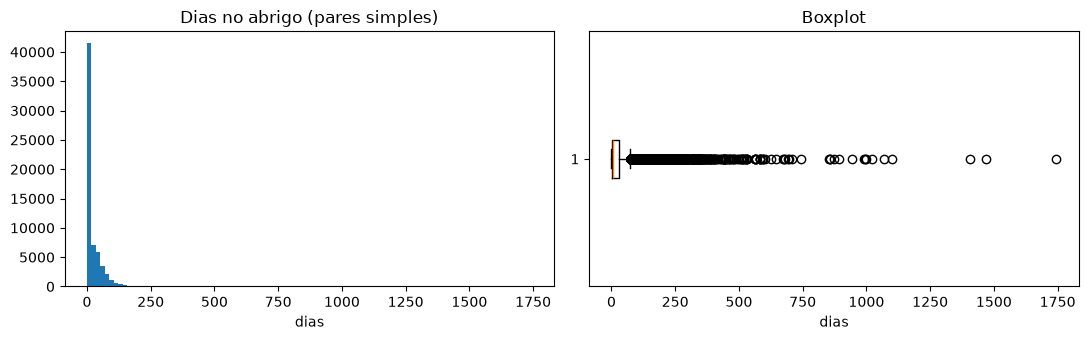

In [47]:
# histograma e boxplot lado a lado: a maioria sai rápido e poucos ficam muito
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(dias, bins=100)
ax[0].set_title("Dias no abrigo (pares simples)")
ax[0].set_xlabel("dias")
ax[1].boxplot(dias, orientation="horizontal")
ax[1].set_title("Boxplot")
ax[1].set_xlabel("dias")
plt.tight_layout()
plt.show()

In [48]:
# regra do IQR (1,5 x intervalo interquartil)
q1, q3 = dias.quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
print(f"Limite superior pelo IQR: {limite:.0f} dias")
print(f"Acima do limite: {(dias > limite).sum()} ({(dias > limite).mean():.1%})")
print("Acima de 1 ano:", (dias > 365).sum())
print("Máximo:", dias.max(), "dias")

Limite superior pelo IQR: 74 dias
Acima do limite: 4381 (6.9%)
Acima de 1 ano: 99
Máximo: 1745 dias


**Achados:**
- A distribuição dos dias no abrigo é **muito assimétrica**: a maioria sai em poucas semanas, mas há uma cauda longa.
- A regra do IQR marcaria quase 7% dos dados como outlier (tudo acima de ~74 dias). Isso acontece porque a distribuição é assimétrica por natureza: um gato ficar 3 meses não é erro.
- Os casos realmente extremos são poucos: cerca de 100 passam de 1 ano (menos de 0,2%) e o máximo chega perto de 5 anos. Não temos como provar se são erro (ex.: uma saída e uma volta que não foram registradas) ou estadias reais.

### 3.13 Adoções com subtipo "Foster"

O `Outcome Subtype` detalha o desfecho. Nas adoções, um subtipo aparece muito: **Foster** (lar temporário). Comparamos o tempo entre entrada e saída por subtipo, usando os mesmos pares simples.

In [49]:
# tempo das adoções por subtipo (o Foster inclui os dias em lar temporário)
adocoes = simples.assign(dias=dias)[simples["Outcome Type"] == "Adoption"]
adocoes.groupby(adocoes["Outcome Subtype"].fillna("(vazio)"))["dias"].agg(["count", "median"])

,count,median
Outcome Subtype,,
(vazio),21770,14.0
Barn,3,7.0
Foster,9406,55.0
Offsite,115,39.0


**Achado:** cerca de 30% das adoções têm subtipo `Foster`, e o tempo entre entrada e saída delas é bem maior que o das adoções sem subtipo. O portal não explica o subtipo, mas o nome sugere que o gato passou um tempo num **lar temporário** antes da adoção ser registrada. Se for isso, o tempo "no abrigo" dessas passagens inclui tempo fora do abrigo.

Não é um erro que dê pra corrigir, porque não sabemos quanto tempo o gato ficou em lar temporário. Mas é uma **limitação importante** para as perguntas sobre tempo até a adoção: o subtipo precisa continuar no dataset para a análise poder separar ou comparar esses casos.

### 3.14 Data de nascimento depois da saída

In [50]:
# nascimento depois da própria saída (os 12)
dob = pd.to_datetime(saidas["Date of Birth"])
print("Nascimento depois da saída:", (dob > sai_dt.dt.normalize()).sum())

Nascimento depois da saída: 12


**Achado:** alguns registros têm data de nascimento posterior à saída (impossível). Como `Date of Birth` só serve aqui para conferir a idade, isso **não afeta** o dataset final.

**Resposta do grupo:**

- **Volume e estrutura:** 69.324 entradas e 69.399 saídas de gatos, 12 colunas em cada base, todas chegando como texto. As datas usam formatos diferentes em cada base e a idade vem como texto ("2 years").
- **Chave:** o `Animal ID` não é único (2.785 gatos têm mais de uma passagem, até 7), então as bases não podem ser unidas só pelo ID.
- **Ausentes:** o nome falta em 39% das entradas, o que não é erro, é o que a pergunta 3 estuda; o desfecho falta em 9 saídas.
- **Valores impossíveis:** 327 saídas com horário antes da entrada (sempre no mesmo dia: o erro é o horário), uma idade negativa e 12 datas de nascimento depois da saída.
- **Categorias:** 18 condições de entrada (várias raras e que mudam com o tempo), 327 cores e 111 raças; `Rto-Adopt` e `Disposal` sem definição no portal.
- **Outliers:** pelo IQR, 6,9% das estadias passariam de 74 dias, o que é normal num abrigo; 99 dos pares simples passam de 1 ano.
- **Esperados, mas que não existem:** diferenças de maiúsculas/minúsculas e conflitos de raça, cor ou sexo entre as bases (0 casos).

Resumo dos 24 problemas e do que foi feito com cada um:

| # | Problema | Onde | Encontrado? | Tratamento (seções 4 a 6) |
|---|---|---|---|---|
| 1 | Base com todos os animais | ambas | sim | filtrar `Animal Type == "Cat"` |
| 2 | Duplicados exatos | ambas | sim, poucos | remover |
| 3 | Mesma entrada registrada 2x (mesmo ID e hora) | entradas | sim, poucos | manter só a primeira |
| 4 | Mesmo gato com várias passagens | ambas | sim, cerca de 4% dos gatos | parear cada entrada com sua saída pelas datas |
| 5 | Entradas sem saída / saídas sem entrada | ambas | sim | entradas sem saída **ficam** marcadas como `sem_saida` (removê-las criaria viés nos anos recentes); saídas sem entrada ficam de fora |
| 6 | Datas como texto, em formatos diferentes, com fuso em parte das linhas | ambas | sim | converter para data |
| 7 | Horário da saída antes da entrada (mesmo dia) | saídas | sim | trabalhar com a **data** e aceitar saída no mesmo dia |
| 8 | Idade em texto, singular/plural misturado | ambas | sim | converter para meses |
| 9 | Idade negativa | ambas | sim, 1 gato | tratar como ausente |
| 10 | "0 years" (às vezes com nascimento poucos dias depois da entrada) | ambas | sim | manter como 0 (recém-nascido ou de poucos dias, confirmado pela data de nascimento e pela idade na saída) |
| 11 | Nome ausente / com `*` / peso, ID ou número no lugar do nome | ambas | sim | criar `tem_nome` e `nome_com_asterisco` |
| 12 | Sexo e castração na mesma coluna | ambas | sim | separar em `sexo` e `castrado` |
| 13 | Condição de entrada com categorias raras e que mudam com o tempo | entradas | sim | padronizar e agrupar as raras |
| 14 | Desfecho ausente e categorias não documentadas | saídas | sim | ausente vira "desconhecido"; `Rto-Adopt` fica separado da adoção (a prefeitura soma com devolução ao dono); `Disposal` fica sem tradução |
| 15 | Cores e raças com centenas de combinações raras | ambas | sim | cor principal, `is_black`, raça principal e agrupamento das raras |
| 16 | Maiúsculas/minúsculas inconsistentes | ambas | **não** | nada a fazer |
| 17 | Raça/cor/sexo diferentes entre as bases | ambas | **não** | nada a fazer |
| 18 | Tempo no abrigo muito longo | junção | sim, poucos casos | manter e sinalizar com uma flag |
| 19 | Idade muito alta (até 22 anos) | ambas | possível, não é erro | manter |
| 20 | Data de nascimento depois da saída | saídas | sim | coluna não entra no dataset final |
| 21 | `MonthYear` redundante e em formato diferente | ambas | sim | descartar |
| 22 | Adoções "Foster": o tempo pode incluir lar temporário | saídas | sim, ~30% das adoções | manter `subtipo_desfecho` no dataset e registrar a limitação para o RA2 |
| 23 | `Nursing` mistura filhote que mama e mãe que amamenta | entradas | sim | manter a categoria sem tradução; a idade separa os dois casos |
| 24 | Bases congeladas em 05/05/2025 | ambas | sim | registrar; explica as entradas sem saída (item 5) |

## 4. Limpeza e preparação dos dados

Realize a limpeza necessária ao projeto. Verifique valores ausentes, duplicados e inconsistências e trate os problemas encontrados, quando necessário.

A partir daqui o processamento é feito com **Apache Spark** (PySpark + Spark SQL): a mesma lógica roda numa máquina só ou num cluster, então o fluxo continua funcionando se a base crescer. A exploração da seção 3 ficou em pandas, porque lá só olhamos os dados.

Cada decisão vem justificada logo acima do código. A regra geral: tratar só o que existe e, quando não dá pra provar que é erro, **manter e sinalizar** em vez de apagar.

> A partir daqui, `entradas` e `saidas` são DataFrames do Spark, lidos de novo dos CSVs brutos.

In [51]:
import os

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

# garante que o Spark use o mesmo Python do notebook (no Windows ele pode pegar outro)
os.environ["PYSPARK_PYTHON"] = sys.executable

# no Windows o Spark precisa do winutils.exe e do hadoop.dll pra gravar em disco
# (o streaming do RA2 grava o checkpoint); eles ficam em C:\hadoop\bin
if os.name == "nt":
    os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
    os.environ["PATH"] = os.path.join(os.environ["HADOOP_HOME"], "bin") + os.pathsep + os.environ["PATH"]

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("adocao-gatinhos")
    # fuso fixo: sem isso o Spark usa o fuso do computador e horários de horário de verão podiam virar nulo
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark.version

'4.2.0'

### 4.1 Carregar os dados brutos e filtrar os gatos

Lemos os CSVs sem `inferSchema`, então tudo vem como texto, igual à seção 3. Já na leitura:
- trocamos os nomes das colunas para snake_case, porque nomes com espaço dão trabalho no Spark SQL;
- criamos uma coluna `linha` com a ordem original do arquivo, que usamos depois para escolher entre registros repetidos de forma reproduzível.

In [52]:
# lemos o CSV e deixamos os nomes das colunas em minúsculo e sem espaço ("Animal ID" -> "animal_id")
def ler_csv(caminho):
    df = spark.read.csv(caminho, header=True)
    novos_nomes = [col.lower().replace(" ", "_") for col in df.columns]
    # "linha" guarda a ordem original do arquivo; usamos pra desempatar nos duplicados
    return df.toDF(*novos_nomes).withColumn("linha", F.monotonically_increasing_id())


entradas_raw = ler_csv("../data/raw/intakes.csv")
saidas_raw = ler_csv("../data/raw/outcomes.csv")

# só gatos
entradas = entradas_raw.filter(F.col("animal_type") == "Cat")
saidas = saidas_raw.filter(F.col("animal_type") == "Cat")

# guarda o bruto dos gatos pra comparar no final
entradas_antes = entradas
saidas_antes = saidas

print("Entradas de gatos:", entradas.count())
print("Saídas de gatos:  ", saidas.count())
entradas.printSchema()

Entradas de gatos: 69324


Saídas de gatos:   69399
root
 |-- animal_id: string (nullable = true)
 |-- name: string (nullable = true)
 |-- datetime: string (nullable = true)
 |-- monthyear: string (nullable = true)
 |-- found_location: string (nullable = true)
 |-- intake_type: string (nullable = true)
 |-- intake_condition: string (nullable = true)
 |-- animal_type: string (nullable = true)
 |-- sex_upon_intake: string (nullable = true)
 |-- age_upon_intake: string (nullable = true)
 |-- breed: string (nullable = true)
 |-- color: string (nullable = true)
 |-- linha: long (nullable = false)



### 4.2 Duplicados

**Decisão:** remover as linhas idênticas, porque são o mesmo registro repetido e contariam o gato duas vezes. A coluna `linha` fica de fora da comparação, já que ela é diferente em cada linha.

Nas entradas, também removemos os registros com o mesmo `animal_id` e o mesmo `datetime`. Um gato não entra duas vezes no mesmo minuto, e as duas versões só mudam o endereço ou o tipo de entrada. Ficamos com a que aparece **primeiro no arquivo**: não há como saber qual está certa, e são só 4 casos.

> No Spark o `dropDuplicates` com algumas colunas fica com uma linha qualquer. Por isso usamos uma *window* com `row_number`, ordenada pela `linha` original.

In [53]:
# duplicados exatos: ignoro a coluna "linha", que é diferente em toda linha
colunas_ent = [c for c in entradas.columns if c != "linha"]
colunas_sai = [c for c in saidas.columns if c != "linha"]

entradas = entradas.dropDuplicates(colunas_ent)
saidas = saidas.dropDuplicates(colunas_sai)

# mesma entrada registrada 2x (mesmo gato e mesma data/hora): ficamos com a primeira
primeira = Window.partitionBy("animal_id", "datetime").orderBy("linha")
entradas = (
    entradas.withColumn("rn", F.row_number().over(primeira))
    .filter(F.col("rn") == 1)
    .drop("rn")
)

print("Entradas:", entradas_antes.count(), "->", entradas.count())
print("Saídas:  ", saidas_antes.count(), "->", saidas.count())

Entradas: 69324 -> 69309


Saídas:   69399 -> 69387


### 4.3 Conversão das datas

**Decisão:** converter `datetime` para timestamp, informando o formato de cada base (eles são diferentes). Nas saídas, o fuso `-05:00` só aparece em linhas à meia-noite, sem horário real, então basta pegar os 19 primeiros caracteres.

In [54]:
# texto -> data/hora, cada base no seu formato
entradas = entradas.withColumn(
    "data_hora_entrada", F.to_timestamp("datetime", "MM/dd/yyyy hh:mm:ss a")
)
saidas = saidas.withColumn(
    "data_hora_saida", F.to_timestamp(F.substring("datetime", 1, 19), "yyyy-MM-dd'T'HH:mm:ss")
)

# se alguma data não tivesse convertido, ia aparecer como nulo aqui
print("Datas inválidas nas entradas:", entradas.filter(F.col("data_hora_entrada").isNull()).count())
print("Datas inválidas nas saídas:  ", saidas.filter(F.col("data_hora_saida").isNull()).count())

Datas inválidas nas entradas: 0


Datas inválidas nas saídas:   0


### 4.4 Idade em meses

**Decisão:** transformar o texto em número de **meses**. Meses é uma boa escala porque a maioria dos gatos é filhote (idades em semanas), mas também há gatos de 20 anos.

- Usamos 1 mês = 30,44 dias e 1 ano = 365,25 dias (médias do calendário).
- "1 week" e "1 weeks" viram a mesma coisa (tiramos o "s" do final).
- **Idade negativa** é impossível, então vira nulo.
- **"0 years"** vira 0. Na seção 3.6 vimos que, na maioria deles, a data de nascimento é igual à data de entrada, e nos outros fica poucos dias depois (o sistema mostra 0 quando a conta daria negativa; na saída, a maioria desses tinha de 1 a 3 meses). Ou seja, são recém-nascidos ou filhotes com poucos dias de vida.

In [55]:
# "2 months" -> número 2 e unidade "month" (tiramos o s do plural)
numero = F.split("age_upon_intake", " ").getItem(0).cast("int")
unidade = F.regexp_replace(F.split("age_upon_intake", " ").getItem(1), "s$", "")

# passamos tudo pra dias e depois dividimos pra virar meses
dias_de_vida = (
    F.when(unidade == "day", numero)
    .when(unidade == "week", numero * 7)
    .when(unidade == "month", numero * 30.44)
    .when(unidade == "year", numero * 365.25)
)

entradas = entradas.withColumn(
    "idade_entrada_meses",
    F.when(dias_de_vida >= 0, F.round(dias_de_vida / 30.44, 1)),  # negativa fica nula
)

entradas.select("age_upon_intake", "idade_entrada_meses").distinct().orderBy("idade_entrada_meses").show(8)

+---------------+-------------------+
|age_upon_intake|idade_entrada_meses|
+---------------+-------------------+
|       -4 years|               NULL|
|          1 day|                0.0|
|        0 years|                0.0|
|         4 days|                0.1|
|         3 days|                0.1|
|         2 days|                0.1|
|         6 days|                0.2|
|         1 week|                0.2|
+---------------+-------------------+
only showing top 8 rows


In [56]:
# confere quantas idades ficaram nulas e se a menor e a maior fazem sentido
entradas.select(
    F.sum(F.col("idade_entrada_meses").isNull().cast("int")).alias("idades_nulas"),
    F.min("idade_entrada_meses").alias("menor"),
    F.max("idade_entrada_meses").alias("maior"),
).show()

+------------+-----+-----+
|idades_nulas|menor|maior|
+------------+-----+-----+
|           1|  0.0|264.0|
+------------+-----+-----+



### 4.5 Nome

**Decisão:** criar duas colunas, sem apagar informação:
- `tem_nome`: o gato chegou com um nome de verdade. É `False` quando o nome está ausente **ou** quando no lugar do nome está o peso do filhote ("103 Grams"), o próprio ID ("A840400") ou só um número ("#2"). Nenhum desses é um nome.
- `nome_com_asterisco`: o nome começa com `*`. Costuma-se dizer que isso indica nome dado pelo abrigo, mas o portal não documenta isso. Guardamos a informação separada para decidir na análise como usar.

In [57]:
# (?i) = ignora maiúsculas/minúsculas
placeholder = r"(?i)^\*?(?:A\d{5,}|#?\d+|\d+\s*(?:g|grams)\b.*|grams\s*\d+)$"
# nome que é peso/ID/número não conta como nome
eh_placeholder = F.coalesce(F.col("name").rlike(placeholder), F.lit(False))

entradas = (
    entradas
    .withColumn("tem_nome", F.col("name").isNotNull() & ~eh_placeholder)
    .withColumn("nome_com_asterisco", F.coalesce(F.col("name").startswith("*"), F.lit(False)))
)

print("Nomes que eram peso/ID/número:", entradas.filter(eh_placeholder).count())
entradas.groupBy("tem_nome").pivot("nome_com_asterisco").count().show()

Nomes que eram peso/ID/número: 2895


+--------+-----+-----+
|tem_nome|false| true|
+--------+-----+-----+
|    true|18474|20845|
|   false|29858|  132|
+--------+-----+-----+



### 4.6 Sexo e castração

**Decisão:** separar `sex_upon_intake` em duas colunas:
- `sexo`: macho / femea / desconhecido
- `castrado`: true (Neutered/Spayed), false (Intact) ou nulo quando é `Unknown`

Usamos a coluna da **entrada** e não a da saída: o abrigo castra muitos gatos antes da adoção, então a castração na saída já seria consequência da passagem pelo abrigo. A pergunta 4 é sobre o gato que **chega** castrado ou não. Como vimos na seção 3.11, o sexo é igual nas duas bases.

In [58]:
# "Neutered Male": a primeira palavra diz a castração e a última, o sexo
primeira_palavra = F.split("sex_upon_intake", " ").getItem(0)
ultima_palavra = F.element_at(F.split("sex_upon_intake", " "), -1)

entradas = (
    entradas
    .withColumn("sexo", F.when(ultima_palavra == "Male", "macho")
                         .when(ultima_palavra == "Female", "femea")
                         .otherwise("desconhecido"))
    .withColumn("castrado", F.when(primeira_palavra.isin("Neutered", "Spayed"), True)
                             .when(primeira_palavra == "Intact", False))
)

entradas.groupBy("sex_upon_intake", "sexo", "castrado").count().orderBy("sex_upon_intake").show()

+---------------+------------+--------+-----+
|sex_upon_intake|        sexo|castrado|count|
+---------------+------------+--------+-----+
|  Intact Female|       femea|   false|26302|
|    Intact Male|       macho|   false|25082|
|  Neutered Male|       macho|    true| 6720|
|  Spayed Female|       femea|    true| 6174|
|        Unknown|desconhecido|    NULL| 5031|
+---------------+------------+--------+-----+



### 4.7 Tipo e condição de entrada

**Tipo de entrada:** a coluna já está limpa. Só traduzimos para português.

**Condição de entrada:** são 18 categorias, muitas raríssimas.
- As principais são traduzidas. `Nursing` fica como está porque é ambígua: na seção 3.9 vimos que a maioria tem poucas semanas (o filhote que mama), mas 177 têm 1 ano ou mais (a mãe que amamenta). Qualquer tradução escolheria um dos dois. Na análise, a `faixa_etaria` separa os casos.
- `Medical`, `Med Attn` e `Med Urgent` viram **atendimento_medico**. Os três indicam necessidade de atenção médica e só aparecem nos anos mais recentes, o que sugere variações de nome no cadastro.
- As outras categorias (menos de 1% cada) viram **outra**.
- Observação para a análise: `Nursing` some em 2022 e `Neonatal` começa em 2021, então comparações entre anos nessas categorias precisam de cuidado.

Para traduzir usamos um dicionário Python transformado num mapa do Spark (`create_map`). O que não está no dicionário recebe um valor padrão.

In [59]:
# troca o valor em inglês pelo do dicionário; o que não está no dicionário vira o padrão
def traduz(coluna, dicionario, padrao):
    mapa = F.create_map(*[F.lit(x) for par in dicionario.items() for x in par])
    return F.coalesce(mapa[F.col(coluna)], F.lit(padrao))


entradas = (
    entradas
    .withColumn("tipo_entrada", traduz("intake_type", {
        "Stray": "perdido",
        "Owner Surrender": "entregue_pelo_dono",
        "Public Assist": "assistencia_publica",
        "Abandoned": "abandonado",
        "Euthanasia Request": "pedido_de_eutanasia",
    }, None))
    .withColumn("condicao_entrada", traduz("intake_condition", {
        "Normal": "normal",
        "Injured": "ferido",
        "Sick": "doente",
        "Nursing": "nursing",
        "Neonatal": "neonatal",
        "Medical": "atendimento_medico",
        "Med Attn": "atendimento_medico",
        "Med Urgent": "atendimento_medico",
    }, "outra"))
)

# confere as categorias novas
for coluna in ["tipo_entrada", "condicao_entrada"]:
    entradas.groupBy(coluna).count().orderBy(F.desc("count")).show()

+-------------------+-----+
|       tipo_entrada|count|
+-------------------+-----+
|            perdido|53610|
| entregue_pelo_dono|13442|
|assistencia_publica| 1449|
|         abandonado|  748|
|pedido_de_eutanasia|   60|
+-------------------+-----+



+------------------+-----+
|  condicao_entrada|count|
+------------------+-----+
|            normal|57019|
|            ferido| 4339|
|            doente| 3285|
|           nursing| 2559|
|          neonatal| 1467|
|             outra|  389|
|atendimento_medico|  251|
+------------------+-----+



**Resposta do grupo:**

| problema (seção 3) | tratamento | resultado |
|---|---|---|
| base com todos os animais | filtro `Animal Type = Cat` | 69.324 entradas e 69.399 saídas |
| duplicados exatos e mesma entrada registrada 2x | remoção; na entrada repetida fica a primeira do arquivo | 23 + 4 linhas removidas |
| datas como texto, em formatos diferentes | conversão com o formato de cada base | 0 datas inválidas |
| idade em texto, idade negativa e "0 years" | idade em meses; a negativa vira vazio; "0 years" é recém-nascido e vira 0 | 1 idade vazia |
| nome ausente ou com peso/ID/número no lugar | `tem_nome` (só nome válido) e `nome_com_asterisco` | 2.895 nomes falsos não contam como nome |
| sexo e castração na mesma coluna | `sexo` e `castrado`, pela entrada | castração vazia nos 5.031 de sexo desconhecido |
| 18 condições de entrada, várias raras | tradução e agrupamento em 7 | `tipo_entrada` e `condicao_entrada` |

Os demais problemas (gatos com várias passagens, saída antes da entrada, estadias longas, desfechos sem definição, cores e raças) são tratados junto com as transformações da seção 5, porque dependem do pareamento das bases. Nada foi apagado sem prova de que era erro.

## 5. Transformação dos dados

Realize as transformações necessárias à análise, como criação de colunas, filtros, agrupamentos, conversões ou junções, quando aplicáveis.

### 5.1 Pareamento de cada entrada com a sua saída

Esse é o passo mais importante. O mesmo gato pode ter várias entradas e saídas, então não dá pra juntar só pelo `animal_id`.

**Regra:** a saída de uma entrada é a **primeira saída do mesmo gato depois dela**, desde que aconteça **antes da próxima entrada** desse gato. Se não existe saída nesse intervalo, a saída dessa passagem não foi registrada.

Antes de parear, numeramos as passagens de cada gato (1ª entrada, 2ª entrada...) e guardamos a data da próxima entrada com `lead`.

In [60]:
# numeramos as passagens de cada gato (1, 2, 3...) e guardamos a data da próxima entrada dele
por_gato = Window.partitionBy("animal_id").orderBy("data_hora_entrada")

entradas = (
    entradas
    .withColumn("passagem", F.row_number().over(por_gato))
    .withColumn("proxima_entrada", F.lead("data_hora_entrada").over(por_gato))
)

# o gato com 7 passagens, de exemplo
entradas.filter(F.col("animal_id") == "A774102") \
    .select("animal_id", "passagem", "data_hora_entrada", "proxima_entrada").show()

+---------+--------+-------------------+-------------------+
|animal_id|passagem|  data_hora_entrada|    proxima_entrada|
+---------+--------+-------------------+-------------------+
|  A774102|       1|2018-06-11 12:53:00|2018-09-07 16:55:00|
|  A774102|       2|2018-09-07 16:55:00|2018-09-28 11:36:00|
|  A774102|       3|2018-09-28 11:36:00|2018-11-28 15:01:00|
|  A774102|       4|2018-11-28 15:01:00|2019-01-07 14:02:00|
|  A774102|       5|2019-01-07 14:02:00|2019-01-25 17:24:00|
|  A774102|       6|2019-01-25 17:24:00|2019-02-21 12:13:00|
|  A774102|       7|2019-02-21 12:13:00|               NULL|
+---------+--------+-------------------+-------------------+



**1ª rodada (Spark SQL):** juntamos cada entrada com as saídas do mesmo gato que ficam entre ela e a próxima entrada, e ficamos com a primeira (`ROW_NUMBER`).

In [61]:
# registramos as tabelas pra poder usar SQL
entradas.createOrReplaceTempView("entradas")
saidas.createOrReplaceTempView("saidas")

# rodada 1: pra cada entrada, a primeira saída depois dela e antes da próxima entrada
# (o ROW_NUMBER numera as saídas candidatas e o rn = 1 fica só com a primeira)
rodada1 = spark.sql("""
    SELECT *
    FROM (
        SELECT e.animal_id, e.passagem, s.data_hora_saida, s.outcome_type, s.outcome_subtype,
               ROW_NUMBER() OVER (PARTITION BY e.animal_id, e.passagem ORDER BY s.data_hora_saida) AS rn
        FROM entradas e
        JOIN saidas s
          ON  s.animal_id = e.animal_id
          AND s.data_hora_saida >= e.data_hora_entrada
          AND (e.proxima_entrada IS NULL OR s.data_hora_saida < e.proxima_entrada)
    )
    WHERE rn = 1
""").drop("rn")

rodada1.createOrReplaceTempView("rodada1")
print("Pareadas na 1ª rodada:", rodada1.count())

Pareadas na 1ª rodada: 68566


**2ª rodada:** na seção 3.5 vimos que algumas saídas têm o **horário** registrado antes da entrada, mas sempre no **mesmo dia**. Como o horário das saídas não é confiável e a data é, para as entradas que ficaram sem par aceitamos uma saída **do mesmo dia** que ainda não tenha sido usada. Cada entrada e cada saída só podem ser usadas uma vez.

In [62]:
# rodada 2: as entradas que ficaram sem par, aceitando saída no mesmo dia,
# porque o horário das saídas não é confiável. LEFT ANTI JOIN = o que não foi usado na rodada 1.
# No fim, cada saída só pode ir pra uma entrada (rn_saida = 1)
rodada2 = spark.sql("""
    WITH entradas_sem_par AS (
        SELECT e.* FROM entradas e
        LEFT ANTI JOIN rodada1 r ON r.animal_id = e.animal_id AND r.passagem = e.passagem
    ),
    saidas_livres AS (
        SELECT s.* FROM saidas s
        LEFT ANTI JOIN rodada1 r ON r.animal_id = s.animal_id AND r.data_hora_saida = s.data_hora_saida
    ),
    candidatos AS (
        SELECT e.animal_id, e.passagem, e.data_hora_entrada,
               s.data_hora_saida, s.outcome_type, s.outcome_subtype,
               ROW_NUMBER() OVER (PARTITION BY e.animal_id, e.passagem ORDER BY s.data_hora_saida) AS rn_entrada
        FROM entradas_sem_par e
        JOIN saidas_livres s
          ON s.animal_id = e.animal_id
         AND to_date(s.data_hora_saida) = to_date(e.data_hora_entrada)
    )
    SELECT animal_id, passagem, data_hora_saida, outcome_type, outcome_subtype
    FROM (
        SELECT *, ROW_NUMBER() OVER (PARTITION BY animal_id, data_hora_saida ORDER BY data_hora_entrada) AS rn_saida
        FROM candidatos
        WHERE rn_entrada = 1
    )
    WHERE rn_saida = 1
""")

print("Pareadas na 2ª rodada (mesmo dia):", rodada2.count())

Pareadas na 2ª rodada (mesmo dia): 333


In [63]:
# juntamos as duas rodadas e colamos em cada entrada; left join pra não perder quem ficou sem saída
saidas_pareadas = rodada1.unionByName(rodada2)
pares = entradas.join(saidas_pareadas, on=["animal_id", "passagem"], how="left")

print("Entradas:", pares.count())
print("Total pareado:", pares.filter(F.col("data_hora_saida").isNotNull()).count())

# confere: nenhuma saída foi usada por duas entradas
saidas_pareadas.groupBy("animal_id", "data_hora_saida").count().filter("count > 1").count()

Entradas: 69309


Total pareado: 68899


0

**Entradas que ficaram sem saída**

Quantas são e em que ano entraram? Também calculamos a porcentagem das entradas de cada ano que ficou sem saída.

In [64]:
# quantas entradas ficaram sem saída em cada ano
por_ano = (
    pares.groupBy(F.year("data_hora_entrada").alias("ano"))
    .agg(
        F.count("*").alias("entradas"),
        F.sum(F.col("data_hora_saida").isNull().cast("int")).alias("sem_saida"),
    )
    .withColumn("pct_sem_saida", F.round(100 * F.col("sem_saida") / F.col("entradas"), 1))
    .orderBy("ano")
)
por_ano.show()

+----+--------+---------+-------------+
| ano|entradas|sem_saida|pct_sem_saida|
+----+--------+---------+-------------+
|2013|    1309|        0|          0.0|
|2014|    6937|        8|          0.1|
|2015|    7484|        3|          0.0|
|2016|    6632|        3|          0.0|
|2017|    6488|        4|          0.1|
|2018|    6018|        0|          0.0|
|2019|    7880|        2|          0.0|
|2020|    3448|        0|          0.0|
|2021|    5112|        0|          0.0|
|2022|    4684|        0|          0.0|
|2023|    5600|        4|          0.1|
|2024|    6046|       14|          0.2|
|2025|    1671|      372|         22.3|
+----+--------+---------+-------------+



A maior parte é de 2025: são gatos que **ainda estavam no abrigo** quando a base parou de ser atualizada (05/05/2025). Nos outros anos são poucos casos, provavelmente saídas que não foram registradas.

**Decisão:** **manter** essas passagens no dataset, com `desfecho = "sem_saida"` e `data_saida`/`dias_no_abrigo` vazios.

Remover parece natural, porque sem saída não há tempo nem desfecho. Mas isso criaria um **viés**. Os gatos que ainda estavam no abrigo em maio/2025 são justamente os que estavam demorando, e eles são uma fatia grande das entradas de 2025 (ver `pct_sem_saida`). Sem eles, os anos mais recentes pareceriam ter estadias mais curtas do que de fato tiveram. Esse tipo de dado é chamado de **censurado**: sabemos que o gato ficou *pelo menos* até 05/05/2025, só não sabemos quando saiu.

Mantendo e marcando essas passagens, a análise decide como tratá-las: excluir de forma consciente, limitar o período analisado ou usar técnicas próprias para dados censurados.

In [65]:
# cache: sem ele o Spark refaz o pareamento inteiro a cada count() daqui pra frente
pares = pares.cache()
print("Passagens:", pares.count())
print("  com saída:", pares.filter(F.col("data_hora_saida").isNotNull()).count())
print("  sem saída:", pares.filter(F.col("data_hora_saida").isNull()).count())

Passagens: 69309


  com saída: 68899


  sem saída: 410


Já as saídas que não tiveram entrada correspondente (gatos que entraram antes de out/2013, quando a base começa, por exemplo) ficam de fora. Sem a entrada não temos as características do gato na chegada nem a data de início.

### 5.2 Datas finais e dias no abrigo

**Decisão:** guardar só a **data** (sem horário) de entrada e de saída e calcular `dias_no_abrigo` como a diferença em dias (`datediff`). O horário das saídas não é confiável (seção 3.5), então usar horas criaria tempos negativos ou imprecisos. Um gato que entra e sai no mesmo dia fica com 0 dias. Nas passagens sem saída, os dias ficam vazios.

**Atenção para a análise:** como vimos na seção 3.13, nas adoções com subtipo `Foster` esse tempo provavelmente inclui dias em lar temporário. Por isso o `subtipo_desfecho` fica no dataset.

In [66]:
# datas sem a hora e dias no abrigo = saída - entrada
pares = (
    pares
    .withColumn("data_entrada", F.to_date("data_hora_entrada"))
    .withColumn("data_saida", F.to_date("data_hora_saida"))
    .withColumn("dias_no_abrigo", F.datediff("data_saida", "data_entrada"))
)

print("Tempos negativos:", pares.filter(F.col("dias_no_abrigo") < 0).count())
pares.select("dias_no_abrigo").summary("count", "mean", "min", "25%", "50%", "75%", "max").show()

Tempos negativos: 0


+-------+------------------+
|summary|    dias_no_abrigo|
+-------+------------------+
|  count|             68899|
|   mean|23.205242456349147|
|    min|                 0|
|    25%|                 2|
|    50%|                 7|
|    75%|                31|
|    max|              1745|
+-------+------------------+



### 5.3 Outliers de tempo no abrigo

**Decisão:** **manter** todas as passagens e criar a flag `estadia_acima_1_ano`.

- A regra do IQR não serve aqui: a distribuição é muito assimétrica e ela marcaria como outlier gatos que ficaram 2 ou 3 meses, o que é normal num abrigo.
- As estadias acima de 1 ano são poucas (menos de 0,2%). Não temos como saber se são reais ou se faltou registrar uma saída e uma volta no meio. Remover seria arriscado: se forem reais, são justamente os gatos que mais demoraram pra ser adotados.
- Com a flag, na análise dá pra rodar as análises com e sem esses casos, ou usar medidas robustas como a mediana.

In [67]:
# quem ficou mais de 1 ano ganha uma flag: marcamos, não apagamos
pares = pares.withColumn("estadia_acima_1_ano", F.col("dias_no_abrigo") > 365)

pares.groupBy("estadia_acima_1_ano").count().show()
pares.filter("estadia_acima_1_ano") \
    .select("animal_id", "data_entrada", "data_saida", "dias_no_abrigo", "outcome_type") \
    .orderBy(F.desc("dias_no_abrigo")).show(5)

+-------------------+-----+
|estadia_acima_1_ano|count|
+-------------------+-----+
|               true|  123|
|              false|68776|
|               NULL|  410|
+-------------------+-----+



+---------+------------+----------+--------------+------------+
|animal_id|data_entrada|data_saida|dias_no_abrigo|outcome_type|
+---------+------------+----------+--------------+------------+
|  A764237|  2017-12-26|2022-10-06|          1745|    Adoption|
|  A702369|  2015-05-12|2019-05-21|          1470|    Adoption|
|  A707965|  2015-07-20|2019-05-28|          1408|    Adoption|
|  A762152|  2017-11-15|2021-04-03|          1235|    Adoption|
|  A669236|  2013-12-17|2016-12-23|          1102|    Adoption|
+---------+------------+----------+--------------+------------+
only showing top 5 rows


**Idade:** a idade máxima é de cerca de 22 anos. É alta, mas possível para um gato, então **mantemos**.

### 5.4 Desfecho

Traduzimos as categorias claras. `Rto-Adopt` e `Disposal` não são explicadas no portal e ficam com o nome original:
- `rto-adopt` **não** entra junto com `adocao`. Num relatório da prefeitura (seção 3.9), ele aparece somado com a devolução ao dono. Mantemos o nome original, mas na análise ele deve ser tratado como devolução, não como adoção.
- `disposal` não tem definição oficial, então não traduzimos pra não inventar um significado.

As poucas saídas sem desfecho viram **desconhecido**, e as passagens sem saída (seção 5.1) viram **sem_saida**. O `outcome_subtype` fica como veio, em `subtipo_desfecho`, porque é um detalhe complementar (e separa as adoções `Foster`).

In [68]:
# quem não tem saída vira "sem_saida"; rto-adopt e disposal ficam com o nome original
pares = (
    pares
    .withColumn("desfecho", F.when(F.col("data_hora_saida").isNull(), "sem_saida").otherwise(traduz("outcome_type", {
        "Adoption": "adocao",
        "Transfer": "transferencia",
        "Return to Owner": "devolvido_ao_dono",
        "Euthanasia": "eutanasia",
        "Died": "morte",
        "Missing": "desaparecido",
        "Relocate": "realocado",
        "Rto-Adopt": "rto-adopt",
        "Disposal": "disposal",
    }, "desconhecido")))
    .withColumn("subtipo_desfecho", F.col("outcome_subtype"))
)

pares.groupBy("desfecho").count().orderBy(F.desc("count")).show()

+-----------------+-----+
|         desfecho|count|
+-----------------+-----+
|           adocao|35433|
|    transferencia|26577|
|devolvido_ao_dono| 2857|
|        eutanasia| 2555|
|            morte|  998|
|        sem_saida|  410|
|        rto-adopt|  249|
|         disposal|  164|
|     desaparecido|   51|
|     desconhecido|    9|
|        realocado|    6|
+-----------------+-----+



### 5.5 Faixa etária

**Decisão:** dividir a idade em três faixas, como na pergunta 2:
- **filhote**: menos de 12 meses
- **adulto**: de 1 a menos de 10 anos
- **idoso**: 10 anos ou mais

Os cortes seguem as fases de vida do gato das diretrizes da AAHA/AAFP (*Feline Life Stage Guidelines*, 2021), que consideram filhote até 1 ano e sênior acima de 10 anos. Juntamos as fases intermediárias ("jovem adulto" e "adulto maduro") em uma só.

In [69]:
# filhote: menos de 1 ano; adulto: até 10 anos; idoso: 10 anos ou mais (corte da AAHA/AAFP)
idade = F.col("idade_entrada_meses")
pares = pares.withColumn(
    "faixa_etaria",
    F.when(idade < 12, "filhote").when(idade < 120, "adulto").when(idade >= 120, "idoso"),
)
pares.groupBy("faixa_etaria").count().orderBy(F.desc("count")).show()

+------------+-----+
|faixa_etaria|count|
+------------+-----+
|     filhote|45783|
|      adulto|21521|
|       idoso| 2004|
|        NULL|    1|
+------------+-----+



### 5.6 Raça

**Decisão:**
1. Ficar só com a **primeira raça** quando há duas separadas por `/`.
2. Tirar o sufixo " Mix". Na prática "Domestic Shorthair" e "Domestic Shorthair Mix" são o mesmo tipo de gato sem raça definida, e o "Mix" só multiplica as categorias.
3. Agrupar em **"Outra"** as raças com menos de 100 passagens (~0,15% da base). Com tão poucos gatos não dá pra comparar nada na análise. Antes de aplicar, testamos outros cortes pra ver se 100 faz sentido.

Para contar quantas passagens cada categoria tem sem sair do DataFrame, usamos `count` numa *window* particionada pela própria categoria.

In [70]:
# categoria com menos de 100 passagens vira "Outra"
def agrupa_raras(df, coluna, minimo=100):
    contagem = F.count("*").over(Window.partitionBy(coluna))
    return df.withColumn(coluna, F.when(contagem >= minimo, F.col(coluna)).otherwise("Outra"))


# raça = primeira raça, sem o "Mix" ("Domestic Shorthair Mix" -> "Domestic Shorthair")
pares = pares.withColumn(
    "raca", F.trim(F.regexp_replace(F.split("breed", "/").getItem(0), " Mix", ""))
)

In [71]:
# por que 100? testando outros cortes: quantas categorias sobram e quanto da base vai pra "Outra"
total = pares.count()
racas = [r["count"] for r in pares.groupBy("raca").count().collect()]
cores = [r["count"] for r in pares.groupBy(F.split("color", "/").getItem(0)).count().collect()]

testes = []
for minimo in [20, 50, 100, 200, 500]:
    testes.append((
        minimo,
        sum(n >= minimo for n in racas) + 1,  # +1 por causa da "Outra"
        round(100 * sum(n for n in racas if n < minimo) / total, 2),
        sum(n >= minimo for n in cores) + 1,
        round(100 * sum(n for n in cores if n < minimo) / total, 2),
    ))
spark.createDataFrame(testes, ["minimo", "racas", "pct_racas_em_outra", "cores", "pct_cores_em_outra"]).show()

+------+-----+------------------+-----+------------------+
|minimo|racas|pct_racas_em_outra|cores|pct_cores_em_outra|
+------+-----+------------------+-----+------------------+
|    20|   16|              0.27|   35|              0.11|
|    50|   12|              0.44|   28|              0.42|
|   100|   10|              0.64|   26|              0.68|
|   200|    7|              1.29|   21|              1.75|
|   500|    5|              2.11|   14|              5.23|
+------+-----+------------------+-----+------------------+



Com o corte de **100**, menos de 1% das passagens vai pra "Outra", tanto em raça quanto em cor, e toda categoria que sobra tem pelo menos 100 gatos pra comparar.
- Com **50**, entrariam raças como Ragdoll e Himalayan, com 60 a 80 gatos. É pouco pra comparar tempo de adoção e só tiraria 0,2% da base da "Outra".
- Com **200**, raças conhecidas como Maine Coon, Manx e Russian Blue (140 a 160 gatos cada) iriam pra "Outra", e a "Outra" das cores passaria de 1,7%.

Então 100 fica no meio: categorias com tamanho mínimo razoável, sem esconder muita coisa.

In [72]:
# aplicamos o corte de 100 na raça
pares = agrupa_raras(pares, "raca")

print("Raças antes:", pares.select("breed").distinct().count(), "-> depois:", pares.select("raca").distinct().count())
pares.groupBy("raca").count().orderBy(F.desc("count")).show()

Raças antes: 111 -> depois: 10


+--------------------+-----+
|                raca|count|
+--------------------+-----+
|  Domestic Shorthair|57856|
|Domestic Medium Hair| 5457|
|   Domestic Longhair| 2488|
|             Siamese| 2046|
|               Outra|  445|
|  American Shorthair|  286|
|            Snowshoe|  285|
|          Maine Coon|  162|
|                Manx|  144|
|        Russian Blue|  140|
+--------------------+-----+



### 5.7 Cor principal e `is_black`

**Decisão:**
- `cor_principal`: a primeira cor antes da `/` ("Brown Tabby/White" → "Brown Tabby"). Cores com menos de 100 passagens viram "Outra", pelo mesmo motivo das raças. Os nomes das cores ficam em inglês, como no portal: muitos são padrões de pelagem sem tradução direta (Tabby, Tortie, Torbie, Calico...).
- `is_black`: `true` só quando o gato é **todo preto**: cor "Black" ou "Black/Black" (a mesma cor repetida, que aparece em cerca de 100 registros). A crença popular da pergunta 1 é sobre o gato preto. "Black/White" (preto e branco) e "Black Tabby" (rajado) têm outra aparência e ficam como `false`, mas continuam aparecendo com cor principal "Black". Assim, na análise dá pra usar as duas definições.

In [73]:
# cor principal = primeira cor ("Black/White" -> "Black")
pares = pares.withColumn("cor_principal", F.split("color", "/").getItem(0))
pares = agrupa_raras(pares, "cor_principal")
# is_black só pro gato todo preto; o frajola fica com cor_principal Black e is_black False
pares = pares.withColumn("is_black", F.col("color").isin("Black", "Black/Black"))

print("Cores antes:", pares.select("color").distinct().count(), "-> depois:", pares.select("cor_principal").distinct().count())
pares.groupBy("cor_principal").count().orderBy(F.desc("count")).show(30)

Cores antes: 327 -> depois: 26


+---------------+-----+
|  cor_principal|count|
+---------------+-----+
|    Brown Tabby|16356|
|          Black|15386|
|   Orange Tabby| 7726|
|           Blue| 4368|
|     Blue Tabby| 4122|
|          White| 4041|
|         Tortie| 3406|
|         Calico| 3268|
|         Torbie| 2628|
|    Cream Tabby| 1890|
|     Lynx Point| 1037|
|     Gray Tabby|  755|
|     Seal Point|  698|
|          Outra|  470|
|    Flame Point|  458|
|         Orange|  456|
|           Gray|  417|
|    Black Tabby|  384|
|    Black Smoke|  285|
|    Lilac Point|  211|
|   Tortie Point|  202|
|   Silver Tabby|  188|
|          Cream|  185|
|     Blue Point|  136|
|          Brown|  124|
|Chocolate Point|  112|
+---------------+-----+



In [74]:
# conferindo: só os gatos todo pretos viram is_black
pares.filter(F.col("cor_principal") == "Black") \
    .groupBy("color", "is_black").count().orderBy(F.desc("count")).show(6)

+------------+--------+-----+
|       color|is_black|count|
+------------+--------+-----+
|       Black|    true| 8974|
| Black/White|   false| 6232|
| Black/Black|    true|  109|
|  Black/Gray|   false|   17|
| Black/Brown|   false|   13|
|Black/Orange|   false|   10|
+------------+--------+-----+
only showing top 6 rows


**Resposta do grupo:**

- **Junção (5.1):** cada entrada foi ligada à primeira saída do mesmo gato depois dela e antes da próxima entrada, em duas rodadas de Spark SQL (a segunda aceita saída no mesmo dia, porque o horário das saídas não é confiável). Uma junção simples pelo ID multiplicaria as linhas. Resultado: 68.899 passagens com saída e 410 sem saída, mantidas como `sem_saida` (dados censurados, quase todas de 2025).
- **Conversão (5.2):** `dias_no_abrigo` = data de saída − data de entrada, sem a hora; os 327 tempos negativos viram 0.
- **Flag (5.3):** `estadia_acima_1_ano` marca 123 passagens, sem apagar nenhuma.
- **Categorias (5.4 a 5.7):** desfecho traduzido; `faixa_etaria` (filhote, adulto, idoso, cortes da AAHA/AAFP); raça e cor principal com as raras em "Outra" (111 → 10 raças e 327 → 26 cores, corte de 100 testado contra 20, 50, 200 e 500); `is_black` só pro gato todo preto.

Todas essas colunas existem pra que as perguntas da seção 1 possam ser respondidas direto do dataset, sem refazer limpeza.

## 6. Conjunto de dados resultante

O dataset final, a checagem de que os problemas foram resolvidos (antes × depois, chave e vazios) e o arquivo salvo.

### 6.1 Montando o dataset final

Ficamos só com as colunas limpas, com nomes em português e snake_case. As colunas que não entram:
- `found_location`: não usada nas perguntas.
- `monthyear`: redundante.
- `date_of_birth`: tem datas impossíveis e a idade já vem da entrada.
- o próprio nome do gato: para as perguntas basta saber se ele tem nome.

In [75]:
# as 19 colunas do dataset final, nessa ordem
colunas = [
    "animal_id", "passagem", "tem_nome", "nome_com_asterisco",
    "data_entrada", "data_saida", "dias_no_abrigo", "estadia_acima_1_ano",
    "idade_entrada_meses", "faixa_etaria", "sexo", "castrado",
    "raca", "cor_principal", "is_black",
    "tipo_entrada", "condicao_entrada", "desfecho", "subtipo_desfecho",
]

gatos = pares.select(colunas).orderBy("data_entrada", "animal_id", "passagem").cache()
gatos.printSchema()
# na vertical, porque são 19 colunas
gatos.show(2, vertical=True)

root
 |-- animal_id: string (nullable = true)
 |-- passagem: integer (nullable = false)
 |-- tem_nome: boolean (nullable = false)
 |-- nome_com_asterisco: boolean (nullable = false)
 |-- data_entrada: date (nullable = true)
 |-- data_saida: date (nullable = true)
 |-- dias_no_abrigo: integer (nullable = true)
 |-- estadia_acima_1_ano: boolean (nullable = true)
 |-- idade_entrada_meses: double (nullable = true)
 |-- faixa_etaria: string (nullable = true)
 |-- sexo: string (nullable = false)
 |-- castrado: boolean (nullable = true)
 |-- raca: string (nullable = true)
 |-- cor_principal: string (nullable = true)
 |-- is_black: boolean (nullable = true)
 |-- tipo_entrada: string (nullable = true)
 |-- condicao_entrada: string (nullable = false)
 |-- desfecho: string (nullable = false)
 |-- subtipo_desfecho: string (nullable = true)



-RECORD 0---------------------------------
 animal_id           | A664235            
 passagem            | 1                  
 tem_nome            | false              
 nome_com_asterisco  | false              
 data_entrada        | 2013-10-01         
 data_saida          | 2013-10-01         
 dias_no_abrigo      | 0                  
 estadia_acima_1_ano | false              
 idade_entrada_meses | 0.2                
 faixa_etaria        | filhote            
 sexo                | desconhecido       
 castrado            | NULL               
 raca                | Domestic Shorthair 
 cor_principal       | Orange             
 is_black            | false              
 tipo_entrada        | perdido            
 condicao_entrada    | normal             
 desfecho            | transferencia      
 subtipo_desfecho    | Partner            
-RECORD 1---------------------------------
 animal_id           | A664236            
 passagem            | 1                  
 tem_nome  

### 6.2 Checagem final: antes × depois

In [76]:
entradas_antes.createOrReplaceTempView("entradas_antes")
saidas_antes.createOrReplaceTempView("saidas_antes")
gatos.createOrReplaceTempView("gatos")

# pares simples do bruto (gatos com 1 entrada e 1 saída), só pra medir "saída antes da entrada" no antes
saida_antes_entrada = spark.sql("""
    WITH e AS (
        SELECT animal_id, to_timestamp(datetime, 'MM/dd/yyyy hh:mm:ss a') AS t
        FROM entradas_antes WHERE animal_id IN (SELECT animal_id FROM entradas_antes GROUP BY animal_id HAVING count(*) = 1)
    ),
    s AS (
        SELECT animal_id, to_timestamp(substring(datetime, 1, 19), "yyyy-MM-dd'T'HH:mm:ss") AS t
        FROM saidas_antes WHERE animal_id IN (SELECT animal_id FROM saidas_antes GROUP BY animal_id HAVING count(*) = 1)
    )
    SELECT count(*) FROM e JOIN s USING (animal_id) WHERE s.t < e.t
""").first()[0]


def conta(df, condicao):
    return df.filter(condicao).count()


# cada linha: o problema, quanto tinha no bruto e quanto sobrou no final
checagem = [
    ("Duplicados exatos (entradas + saídas)",
     entradas_antes.count() - entradas_antes.dropDuplicates(colunas_ent).count()
     + saidas_antes.count() - saidas_antes.dropDuplicates(colunas_sai).count(),
     gatos.count() - gatos.dropDuplicates().count()),
    ("Mesma entrada registrada 2x (ID + data/hora)",
     entradas_antes.dropDuplicates(colunas_ent).count()
     - entradas_antes.dropDuplicates(["animal_id", "datetime"]).count(),
     entradas.count() - entradas.dropDuplicates(["animal_id", "datetime"]).count()),
    ("Saída antes da entrada", saida_antes_entrada, conta(gatos, "dias_no_abrigo < 0")),
    ("Idade negativa", conta(entradas_antes, "age_upon_intake LIKE '-%'"), conta(gatos, "idade_entrada_meses < 0")),
    ("Colunas de data guardadas como texto",
     sum(tipo == "string" for nome, tipo in entradas_antes.dtypes + saidas_antes.dtypes if nome == "datetime"),
     sum(tipo == "string" for nome, tipo in gatos.dtypes if nome in ("data_entrada", "data_saida"))),
    ("Categorias de condição de entrada",
     entradas_antes.select("intake_condition").distinct().count(), gatos.select("condicao_entrada").distinct().count()),
    ("Categorias de cor", entradas_antes.select("color").distinct().count(), gatos.select("cor_principal").distinct().count()),
    ("Categorias de raça", entradas_antes.select("breed").distinct().count(), gatos.select("raca").distinct().count()),
    ("Desfecho ausente", conta(saidas_antes, "outcome_type IS NULL"), conta(gatos, "desfecho = 'desconhecido'")),
    ("Categorias de sexo (misturadas com castração)",
     entradas_antes.select("sex_upon_intake").distinct().count(), gatos.select("sexo").distinct().count()),
]
spark.createDataFrame(checagem, ["problema", "antes", "depois"]).show(truncate=False)

+---------------------------------------------+-----+------+
|problema                                     |antes|depois|
+---------------------------------------------+-----+------+
|Duplicados exatos (entradas + saídas)        |23   |0     |
|Mesma entrada registrada 2x (ID + data/hora) |4    |0     |
|Saída antes da entrada                       |327  |0     |
|Idade negativa                               |1    |0     |
|Colunas de data guardadas como texto         |2    |0     |
|Categorias de condição de entrada            |18   |7     |
|Categorias de cor                            |327  |26    |
|Categorias de raça                           |111  |10    |
|Desfecho ausente                             |9    |9     |
|Categorias de sexo (misturadas com castração)|5    |3     |
+---------------------------------------------+-----+------+



Notas sobre a tabela:
- "Mesma entrada registrada 2x": o "depois" é medido nas entradas já limpas, antes do pareamento.
- "Colunas de data guardadas como texto": as datas vinham como texto em três formatos diferentes (entradas, saídas sem fuso e saídas com fuso). Agora são do tipo `date`.
- "Categorias de sexo": antes eram 5 valores misturando sexo e castração; agora são 3 (macho, femea, desconhecido) e a castração está em `castrado`.
- "Desfecho ausente" não vai a zero de propósito: os poucos casos ficaram marcados como `desconhecido`, em vez de sumirem.

Também conferimos a **chave** do dataset: cada linha tem que ser uma passagem diferente (`animal_id` + `passagem`), e a numeração das passagens de cada gato tem que ir de 1 até o total dele, sem pular número. Se o pareamento tivesse duplicado ou perdido alguma entrada, apareceria aqui.

In [77]:
print("Linhas:", gatos.count())
print("Chaves diferentes (animal_id + passagem):", gatos.select("animal_id", "passagem").distinct().count())

# gato com 3 passagens tem que ter passagem 1, 2 e 3: a maior tem que ser igual à quantidade
pulos = (
    gatos.groupBy("animal_id")
    .agg(F.max("passagem").alias("maior"), F.count("*").alias("quantidade"))
    .filter("maior != quantidade")
)
print("Gatos com numeração de passagem quebrada:", pulos.count())

Linhas: 69309


Chaves diferentes (animal_id + passagem): 69309


Gatos com numeração de passagem quebrada: 0


In [78]:
# nulos por coluna no dataset final
gatos.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in colunas]).toPandas().T \
    .rename(columns={0: "nulos"}).query("nulos > 0")

,nulos
data_saida,410
dias_no_abrigo,410
estadia_acima_1_ano,410
idade_entrada_meses,1
faixa_etaria,1
castrado,5031
subtipo_desfecho,28995


Os únicos ausentes que sobram são esperados:
- `data_saida`, `dias_no_abrigo` e `estadia_acima_1_ano`: as passagens com `desfecho = "sem_saida"` (seção 5.1).
- `idade_entrada_meses` e `faixa_etaria`: o gato com idade negativa.
- `castrado`: gatos com sexo `Unknown`, em que a castração não é conhecida.
- `subtipo_desfecho`: detalhe opcional que o abrigo nem sempre preenche.

In [79]:
# período coberto, total de passagens e de gatos, e o resumo dos números
gatos.select(
    F.min("data_entrada").alias("primeira_entrada"),
    F.max("data_saida").alias("ultima_saida"),
    F.count("*").alias("passagens"),
    F.countDistinct("animal_id").alias("gatos_diferentes"),
).show()
gatos.select("dias_no_abrigo", "idade_entrada_meses").summary().show()

+----------------+------------+---------+----------------+
|primeira_entrada|ultima_saida|passagens|gatos_diferentes|
+----------------+------------+---------+----------------+
|      2013-10-01|  2025-05-05|    69309|           66239|
+----------------+------------+---------+----------------+



+-------+------------------+-------------------+
|summary|    dias_no_abrigo|idade_entrada_meses|
+-------+------------------+-------------------+
|  count|             68899|              69308|
|   mean|23.205242456349147| 15.410218156634153|
| stddev| 42.86076027667327|  30.30978653200866|
|    min|                 0|                0.0|
|    25%|                 2|                0.9|
|    50%|                 7|                2.0|
|    75%|                31|               12.0|
|    max|              1745|              264.0|
+-------+------------------+-------------------+



### 6.3 Salvando o dataset do RA1

O resultado (~69 mil linhas) cabe tranquilo na memória, então convertemos para pandas e salvamos **um único CSV**. O `write.csv` do Spark criaria uma pasta com vários arquivos `part-*` e, no Windows, ainda exigiria o `winutils.exe` do Hadoop.

In [80]:
final = gatos.toPandas()
# inteiro com vazio vira float no pandas ("5.0"); Int64 mantém "5" e deixa o vazio
final["dias_no_abrigo"] = final["dias_no_abrigo"].astype("Int64")
final.to_csv("../data/processed/gatos_ra1.csv", index=False)

# relê o arquivo pra garantir que salvou certinho, agora deixando o Spark descobrir os tipos
conferencia = spark.read.csv("../data/processed/gatos_ra1.csv", header=True, inferSchema=True)
print(conferencia.count(), "linhas x", len(conferencia.columns), "colunas")
conferencia.printSchema()

69309 linhas x 19 colunas
root
 |-- animal_id: string (nullable = true)
 |-- passagem: integer (nullable = true)
 |-- tem_nome: boolean (nullable = true)
 |-- nome_com_asterisco: boolean (nullable = true)
 |-- data_entrada: date (nullable = true)
 |-- data_saida: date (nullable = true)
 |-- dias_no_abrigo: integer (nullable = true)
 |-- estadia_acima_1_ano: boolean (nullable = true)
 |-- idade_entrada_meses: double (nullable = true)
 |-- faixa_etaria: string (nullable = true)
 |-- sexo: string (nullable = true)
 |-- castrado: boolean (nullable = true)
 |-- raca: string (nullable = true)
 |-- cor_principal: string (nullable = true)
 |-- is_black: boolean (nullable = true)
 |-- tipo_entrada: string (nullable = true)
 |-- condicao_entrada: string (nullable = true)
 |-- desfecho: string (nullable = true)
 |-- subtipo_desfecho: string (nullable = true)



Relendo com `inferSchema=True`, todas as colunas voltam com o tipo certo: datas como `date`, `dias_no_abrigo` e `passagem` como inteiro, a idade como `double` e as flags como `boolean`. Então quem usar o CSV no RA2 não precisa refazer conversão nenhuma (no pandas, basta passar `parse_dates=["data_entrada", "data_saida"]`).

O arquivo `data/processed/gatos_ra1.csv` é o ponto de partida das próximas etapas, incluindo a simulação do RA2.

## 7. Considerações do RA1

Registre brevemente:

- O que o grupo descobriu sobre os dados.
- Quais dificuldades ou limitações encontrou.
- Como os dados preparados poderão ser utilizados nas próximas etapas.

**Resposta do grupo:**

**O que descobrimos:** a base parece simples (uma linha por evento), mas o mesmo gato pode passar várias vezes pelo abrigo, e isso obrigou a parear entrada e saída pelas datas. O horário das saídas não é confiável (horários padrão como 09:00 e 00:00), mas a data é. Muitos "problemas" não eram erros: "0 years" são recém-nascidos, gato sem nome é o objeto da pergunta 3 e as estadias longas são normais num abrigo.

**Dificuldades e limitações:**
- o portal não tem dicionário de dados: o significado das colunas foi deduzido dos valores, e `Disposal` e o asterisco nos nomes continuam sem definição;
- as 410 passagens `sem_saida` são dados censurados (o gato ficou *pelo menos* até 05/05/2025);
- o tempo das adoções `Foster` pode incluir dias em lar temporário;
- é um abrigo só e os dados mostram associação, não causa.

**Próximas etapas:** o `gatos_ra1.csv` tem uma linha por passagem, com todas as colunas das perguntas já limpas. A análise compara a chance e a mediana do tempo até a adoção entre os grupos de cada pergunta, dentro de cada faixa etária. No RA2, ele serve de base pra gerar registros artificiais coerentes com o abrigo.

---

# RA2 – Streaming Data Processing and Time Windows

Utilize os dados e o contexto do projeto para demonstrar o processamento em streaming e a aplicação de janelas temporais. Escolha um dos cenários:

- **Cenário A – Dados estáticos:** simule a chegada de novos registros utilizando dados artificiais coerentes com o contexto do projeto.
- **Cenário B – Dados em streaming:** utilize sua própria fonte de dados contínuas, sem necessidade de simulação.

## 8. Objetivo da análise em streaming

Responda brevemente:

- O que o grupo deseja monitorar ou analisar?
- Qual informação espera obter com o processamento em streaming?

**Resposta do grupo:**

Queremos monitorar as **adoções do abrigo à medida que elas são registradas**. Para cada dia, o processamento informa:
- quantos gatos foram adotados;
- quantos deles eram gatos pretos (ligado à pergunta 1);
- a mediana de dias que os adotados esperaram no abrigo.

É o tipo de acompanhamento que o abrigo poderia ter num painel: ver no fim de cada dia se as adoções estão no ritmo normal e se os gatos pretos estão sendo adotados, sem esperar um relatório mensal.

## 9. Fonte de dados e processamento

- Informe o cenário escolhido: dados reais em streaming ou simulação.
- Explique brevemente como os novos registros chegam.
- Implemente o processamento em tempo real.
- Demonstre o recebimento de novos registros.

**Resposta do grupo:**

**Cenário A (dados estáticos):** a base do abrigo está congelada desde maio de 2025, então simulamos a chegada de novas adoções como se o abrigo continuasse mandando dados depois que a base parou (06 a 08/05/2025).

**Registros artificiais coerentes com o abrigo:** cada registro é uma adoção (`id_adocao`, `momento_adocao`, `faixa_etaria`, `is_black`, `dias_no_abrigo`). As características vêm de um sorteio, com semente fixa, entre as adoções reais do último ano da base (sem as `Foster`, cujo tempo inclui lar temporário). Assim a proporção de gatos pretos, de filhotes e o tempo de espera seguem o que acontece no abrigo. A quantidade por dia segue a média real de adoções de gatos por dia, e o horário é sorteado dentro do expediente (11h às 19h). O `id` e o horário são inventados.

**Como os registros chegam:** os registros são divididos em **4 lotes**, cada um gravado como um arquivo JSON numa pasta (`data/streaming/adocoes/`), um de cada vez, como se o sistema do abrigo exportasse as adoções novas de tempos em tempos. Um dos lotes traz uma adoção **atrasada** (aconteceu num dia anterior, mas só foi lançada depois).

**Processamento:** o Spark Structured Streaming lê essa pasta com `readStream` (fonte de arquivos, esquema fixo e um arquivo por micro-lote com `maxFilesPerTrigger = 1`). Cada arquivo novo que aparece vira um micro-lote, e o resultado da agregação é atualizado.

In [81]:
import shutil

import numpy as np

PASTA_STREAM = Path("../data/streaming")
PASTA_ADOCOES = PASTA_STREAM / "adocoes"        # onde os lotes "chegam"
PASTA_CHECKPOINT = PASTA_STREAM / "checkpoint"   # onde o Spark guarda o que já processou

# se a demonstração for rodada de novo, para a consulta anterior antes de apagar o checkpoint
for q in spark.streams.active:
    q.stop()

# começa do zero a cada execução, pra demonstração sempre mostrar a chegada dos lotes
shutil.rmtree(PASTA_STREAM, ignore_errors=True)
PASTA_ADOCOES.mkdir(parents=True)

# adoções reais do último ano da base, sem as Foster: é daqui que saem as características
gatos_pd = pd.read_csv("../data/processed/gatos_ra1.csv", parse_dates=["data_entrada", "data_saida"])
adocoes_reais = gatos_pd[
    (gatos_pd["desfecho"] == "adocao")
    & (gatos_pd["subtipo_desfecho"] != "Foster")
    & (gatos_pd["data_saida"] >= "2024-05-06")
]
media_dia = adocoes_reais.groupby("data_saida").size().mean()
print(f"Adoções reais usadas no sorteio: {len(adocoes_reais)} | média de {media_dia:.1f} por dia")
# referência pra comparar com o resultado da simulação na seção 11
print(f"Nelas: {adocoes_reais['is_black'].mean():.1%} de gatos pretos | mediana de {adocoes_reais['dias_no_abrigo'].median():.0f} dias de espera")

Adoções reais usadas no sorteio: 2814 | média de 8.1 por dia
Nelas: 12.4% de gatos pretos | mediana de 13 dias de espera


In [82]:
# semente fixa: toda execução gera os mesmos registros
rng = np.random.default_rng(2025)

registros = []
for dia in pd.date_range("2025-05-06", periods=3):
    n = rng.poisson(media_dia)                       # quantas adoções nesse dia
    sorteio = adocoes_reais.sample(n, random_state=int(rng.integers(1_000_000)))
    # horário sorteado entre 11h e 19h, em ordem
    momentos = dia + pd.to_timedelta(np.sort(rng.integers(11 * 60, 19 * 60, size=n)), unit="min")
    for (_, gato), momento in zip(sorteio.iterrows(), momentos):
        registros.append({
            "momento_adocao": momento,
            "faixa_etaria": gato["faixa_etaria"],
            "is_black": bool(gato["is_black"]),
            "dias_no_abrigo": int(gato["dias_no_abrigo"]),
        })

simulado = pd.DataFrame(registros)
simulado.insert(0, "id_adocao", [f"SIM-{i:03d}" for i in range(1, len(simulado) + 1)])

# os 4 lotes: dia 06 inteiro, dia 07 de manhã, dia 07 à tarde e dia 08
momento = simulado["momento_adocao"]
simulado["lote"] = np.select(
    [momento < "2025-05-07", momento < "2025-05-07 15:00", momento < "2025-05-08"],
    [1, 2, 3],
    default=4,
)
# a última adoção do dia 06 foi lançada atrasada: só chega no lote 3
atrasada = simulado.index[simulado["lote"] == 1][-1]
simulado.loc[atrasada, "lote"] = 3

print("Registros por lote:", simulado.groupby("lote").size().to_dict())
simulado.head(8)

Registros por lote: {1: 10, 2: 3, 3: 5, 4: 14}


,id_adocao,momento_adocao,faixa_etaria,is_black,dias_no_abrigo,lote
0,SIM-001,2025-05-06 11:30:00,adulto,False,19,1
1,SIM-002,2025-05-06 12:13:00,filhote,False,9,1
2,SIM-003,2025-05-06 12:20:00,filhote,True,42,1
3,SIM-004,2025-05-06 12:45:00,adulto,False,116,1
4,SIM-005,2025-05-06 13:46:00,filhote,False,4,1
5,SIM-006,2025-05-06 14:23:00,filhote,False,8,1
6,SIM-007,2025-05-06 14:50:00,filhote,False,59,1
7,SIM-008,2025-05-06 14:55:00,filhote,False,11,1


In [83]:
# o esquema é fixo: no streaming o Spark não pode ficar descobrindo os tipos a cada arquivo
esquema = "id_adocao STRING, momento_adocao TIMESTAMP, faixa_etaria STRING, is_black BOOLEAN, dias_no_abrigo INT"

adocoes_stream = (
    spark.readStream
    .schema(esquema)
    .option("maxFilesPerTrigger", 1)   # um arquivo (lote) por micro-lote
    .json(str(PASTA_ADOCOES))
)

print("É streaming?", adocoes_stream.isStreaming)
adocoes_stream.printSchema()

É streaming? True
root
 |-- id_adocao: string (nullable = true)
 |-- momento_adocao: timestamp (nullable = true)
 |-- faixa_etaria: string (nullable = true)
 |-- is_black: boolean (nullable = true)
 |-- dias_no_abrigo: integer (nullable = true)



## 10. Aplicação de janelas temporais

- Utilize uma janela **Tumbling** (intervalos sem sobreposição) ou **Sliding** (intervalos que podem se sobrepor).
- Informe o tipo e a duração da janela e o deslocamento, quando aplicável.
- Implemente uma agregação coerente com a análise, como contagem, soma ou média.
- Explique brevemente o que será calculado em cada intervalo.

O foco é demonstrar a compreensão do conceito; não é necessário justificar tecnicamente a duração escolhida.

**Resposta do grupo:**

- **Tipo:** janela **Tumbling** (sem sobreposição), sobre o `momento_adocao`, ou seja, o horário em que a adoção aconteceu (*event time*), e não o horário em que o registro chegou.
- **Duração:** 1 dia. Como a janela é tumbling, o deslocamento é igual à duração (1 dia): cada adoção cai em exatamente um dia, como num relatório diário.
- **Agregação em cada janela:**
  - `adocoes`: contagem das adoções do dia;
  - `gatos_pretos`: soma de `is_black` (quantos adotados eram pretos);
  - `pct_pretos`: gatos pretos ÷ adoções;
  - `mediana_dias_espera`: mediana aproximada (`percentile_approx`) dos dias no abrigo. Usamos a mediana pelo mesmo motivo do RA1: o tempo no abrigo é muito assimétrico.
- **Modo de saída:** `complete`, numa tabela em memória (*memory sink*). A cada micro-lote a tabela inteira é recalculada, então dá pra ver uma janela que já existia mudar quando chega uma adoção atrasada. Numa aplicação real, com fluxo infinito, usaríamos `withWatermark` com o modo `update` pra descartar janelas antigas: no modo `complete` o Spark guarda todas as janelas pra sempre, mesmo com watermark.

In [84]:
# poucas partições: os micro-lotes são pequenos (o padrão de 200 deixaria cada lote lento)
spark.conf.set("spark.sql.shuffle.partitions", 4)

# janela tumbling de 1 dia sobre o momento da adoção
adocoes_por_dia = (
    adocoes_stream
    .groupBy(F.window("momento_adocao", "1 day").alias("janela"))
    .agg(
        F.count("*").alias("adocoes"),
        F.sum(F.col("is_black").cast("int")).alias("gatos_pretos"),
        F.percentile_approx("dias_no_abrigo", 0.5).alias("mediana_dias_espera"),
    )
    .withColumn("pct_pretos", F.round(100 * F.col("gatos_pretos") / F.col("adocoes"), 1))
)

consulta = (
    adocoes_por_dia.writeStream
    .outputMode("complete")
    .format("memory")
    .queryName("adocoes_por_dia")
    .option("checkpointLocation", str(PASTA_CHECKPOINT))
    .start()
)
print("Consulta ativa:", consulta.isActive)

Consulta ativa: True


## 11. Resultados e interpretação

Apresente os resultados do processamento e demonstre como a análise se comporta com a chegada de novos registros.

In [85]:
def mostra_resultado():
    spark.sql("""
        SELECT date_format(janela.start, 'dd/MM/yyyy') AS dia,
               adocoes, gatos_pretos, pct_pretos, mediana_dias_espera
        FROM adocoes_por_dia
        ORDER BY janela.start
    """).show()


# cada volta = um lote novo chegando na pasta
for numero, lote in simulado.groupby("lote"):
    registros_lote = lote.drop(columns="lote").assign(
        momento_adocao=lote["momento_adocao"].dt.strftime("%Y-%m-%d %H:%M:%S")
    )
    # grava fora da pasta e depois move: o Spark nunca vê um arquivo pela metade
    temporario = PASTA_STREAM / f"lote_{numero}.tmp"
    registros_lote.to_json(temporario, orient="records", lines=True)
    ja_processados = len(consulta.recentProgress)
    temporario.replace(PASTA_ADOCOES / f"lote_{numero}.json")

    consulta.processAllAvailable()   # espera o Spark processar o que chegou
    # o progresso de cada micro-lote diz quantos registros ele recebeu
    novos = consulta.recentProgress[ja_processados:]
    recebidos = sum(p["numInputRows"] for p in novos)
    dias = ", ".join(sorted(lote["momento_adocao"].dt.strftime("%d/%m").unique()))
    print(f"Lote {numero} chegou: {recebidos} registros novos (adoções de {dias}) "
          f"-> micro-lote {novos[-1]['batchId']}")
    mostra_resultado()

Lote 1 chegou: 10 registros novos (adoções de 06/05) -> micro-lote 0


+----------+-------+------------+----------+-------------------+
|       dia|adocoes|gatos_pretos|pct_pretos|mediana_dias_espera|
+----------+-------+------------+----------+-------------------+
|06/05/2025|     10|           1|      10.0|                  9|
+----------+-------+------------+----------+-------------------+



Lote 2 chegou: 3 registros novos (adoções de 07/05) -> micro-lote 1
+----------+-------+------------+----------+-------------------+
|       dia|adocoes|gatos_pretos|pct_pretos|mediana_dias_espera|
+----------+-------+------------+----------+-------------------+
|06/05/2025|     10|           1|      10.0|                  9|
|07/05/2025|      3|           1|      33.3|                  7|
+----------+-------+------------+----------+-------------------+



Lote 3 chegou: 5 registros novos (adoções de 06/05, 07/05) -> micro-lote 2
+----------+-------+------------+----------+-------------------+
|       dia|adocoes|gatos_pretos|pct_pretos|mediana_dias_espera|
+----------+-------+------------+----------+-------------------+
|06/05/2025|     11|           1|       9.1|                  9|
|07/05/2025|      7|           1|      14.3|                  7|
+----------+-------+------------+----------+-------------------+



Lote 4 chegou: 14 registros novos (adoções de 08/05) -> micro-lote 3
+----------+-------+------------+----------+-------------------+
|       dia|adocoes|gatos_pretos|pct_pretos|mediana_dias_espera|
+----------+-------+------------+----------+-------------------+
|06/05/2025|     11|           1|       9.1|                  9|
|07/05/2025|      7|           1|      14.3|                  7|
|08/05/2025|     14|           2|      14.3|                 22|
+----------+-------+------------+----------+-------------------+



Pra conferir que o streaming chegou no resultado certo, fazemos a mesma agregação **em lote** (`spark.read`, não `readStream`) sobre todos os arquivos que chegaram. As duas tabelas têm que ser iguais.

In [86]:
# a mesma conta em lote, lendo todos os arquivos de uma vez
em_lote = (
    spark.read.schema(esquema).json(str(PASTA_ADOCOES))
    .groupBy(F.window("momento_adocao", "1 day").alias("janela"))
    .agg(
        F.count("*").alias("adocoes"),
        F.sum(F.col("is_black").cast("int")).alias("gatos_pretos"),
        F.percentile_approx("dias_no_abrigo", 0.5).alias("mediana_dias_espera"),
    )
    .withColumn("pct_pretos", F.round(100 * F.col("gatos_pretos") / F.col("adocoes"), 1))
)
streaming = spark.table("adocoes_por_dia")

diferencas = streaming.exceptAll(em_lote).count() + em_lote.exceptAll(streaming).count()
print("Registros simulados:", len(simulado), "| processados pelo streaming:",
      streaming.agg(F.sum("adocoes")).first()[0])
print("Linhas diferentes entre streaming e lote:", diferencas)

consulta.stop()

Registros simulados: 32 | processados pelo streaming: 32
Linhas diferentes entre streaming e lote: 0


**Resposta do grupo:**

Cada lote que chegou virou um micro-lote (0 a 3), e o número de registros recebidos bate com o tamanho de cada lote (10, 3, 5 e 14). A tabela muda a cada chegada:
- **lote 1:** aparece a janela de 06/05, com 10 adoções;
- **lote 2:** aparece a janela de 07/05 com as 3 adoções da manhã, e a de 06/05 não muda;
- **lote 3:** completa o dia 07 (de 3 para 7 adoções) e traz a adoção **atrasada** de 06/05: a janela de 06/05, que parecia fechada, passa de 10 para 11 adoções e o percentual de pretos cai de 10% para 9,1%. Isso acontece porque a janela usa o momento da adoção (*event time*), e não a hora em que o registro chegou;
- **lote 4:** abre a janela de 08/05, com 14 adoções.

Com poucas adoções, o percentual oscila muito: em 07/05 ele foi de 33,3% (1 de 3, só a manhã) para 14,3% com o dia completo. Por isso o número de um dia só faz sentido depois que a janela está completa. No total, 4 dos 32 adotados eram pretos (12,5%), e as medianas de espera ficaram entre 7 e 22 dias, perto do que acontece nas adoções reais usadas no sorteio (12,4% de pretos e mediana de 13 dias, seção 9). Isso mostra que a simulação é coerente com o abrigo.

A conferência final mostra que o streaming chegou no mesmo resultado que a conta em lote sobre todos os arquivos (32 registros, 0 linhas diferentes): processar aos poucos não perdeu nem duplicou nenhum registro. Como os dados são artificiais, esses números **não respondem** à pergunta 1; eles só demonstram o funcionamento.

## 12. Considerações do RA2

Responda brevemente:

- O que foi possível observar com o processamento em streaming?
- Qual foi a contribuição das janelas temporais para a análise?
- Essa abordagem faria sentido em uma aplicação real do projeto? Por quê?

Na última resposta, o grupo pode reconhecer que o streaming foi utilizado apenas como exercício didático, se esse for o caso.

**Resposta do grupo:**

**O que deu pra observar:** a cada arquivo novo, o Spark processou só o que era novo (o checkpoint guarda o que já foi lido) e atualizou o estado das janelas, sem reprocessar tudo. O resultado final foi igual ao do processamento em lote.

**Contribuição das janelas:** a janela de 1 dia transforma um fluxo de registros soltos num resumo diário que dá pra comparar de um dia pro outro. E, por ser baseada no momento do evento, ela colocou a adoção lançada com atraso no dia certo, em vez de contá-la no dia em que chegou.

**Faria sentido numa aplicação real?** Para o nosso projeto, foi um **exercício didático**: a base de Austin está congelada, e as perguntas (que características se associam à adoção ao longo de 11 anos) se respondem melhor em lote, com o histórico inteiro. Num abrigo com o sistema ativo, um monitoramento diário como este poderia servir de alerta, por exemplo se os gatos pretos ou idosos pararem de ser adotados numa semana. Mas, com cerca de 8 adoções de gatos por dia, um relatório diário em lote já resolveria. O streaming compensa quando o volume é grande ou quando é preciso reagir na hora.

In [87]:
# fecha o Spark
spark.stop()